# Benchmarking

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 16.11.2025
- Date of Last Modification: 16.12.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [5]:
import os
import pickle
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from scipy.special import softmax
from datasets import concatenate_datasets, load_from_disk
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split

from app.inference import (embed_dataset,
                           get_average_gene_embed,
                           get_gene_embed,
                           harmonize_adata,
                           perturb_dataset,
                           tokenize_adata)
from nichejepa.evaluation import (compute_neighborhood_composition,
                                  get_adata_cellphonedb_lr_pairs,
                                  get_adata_omnipath_lr_pairs,
                                  knn_classifier,
                                  linear_classifier,
                                  linear_regressor,
                                  plot_roc_curve)
from nichejepa.preprocessors.filters import filter_cells
from nichejepa.preprocessors.graph import construct_neighbor_graph

from analysis_utils import *

INFO:root:Downloading data from `https://omnipathdb.org/queries/enzsub?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/queries/interactions?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/queries/complexes?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/queries/annotations?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/queries/intercell?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/about?format=text`


## 1.2 Define Params

In [6]:
#model_timestamp = '01112025_081731_614'
model_timestamp = '14112025_074547_785'

# Inference params
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
force_recompute_output_embed = False

# Tokenizer params
num_shards = 32
nproc = 4
n_neighs = 10
force_retokenize = False

# Harmonization params
min_cells_per_gene = 0

## 1.3 Configure Paths

In [7]:
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'
model_folder_path = f'{artifacts_folder_path}/models/{model_timestamp}'
cache_directory_path = f'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/cache'

In [8]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)

## 1.4 Run Notebook Setup

In [9]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [10]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [11]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [12]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

# 2. Experiments

## 2.1 xhs1000-39b_1p (Xenium Human Skin Eczema)

In [75]:
# Dataset variables
dataset_name = 'xhs1000-39b_1p'
cell_type_key = 'annotation_new7'
niche_key = 'NICHE_NAMES'
sample_key = 'sample'
batch_key = 'batch'
file_paths = [
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch11.h5ad', # held out from pretraining
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch19.h5ad', # held out from pretraining
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch32.h5ad', # held out from pretraining
]
spot_size = 20

### 2.1.1 Visualize Ground Truth Niches

In [76]:
adata_list = []

for file_path in file_paths:
    # Load AnnData
    adata = sc.read_h5ad(file_path)

    # Harmonize AnnData
    adata = harmonize_adata(adata,
                            min_cells_per_gene=min_cells_per_gene)
    adata.obs[batch_key] = adata.uns[batch_key]
    adata_list.append(adata)

STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...
Number of genes with matching ensembl IDs: 4948.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 10 genes.
Filtering genes expressed in less than 0 cells.
STEP 4: ADDING SPECIAL VALUES...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...
Number of genes with matching ensembl IDs: 4948.
Number of genes skipped

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...
Number of genes with matching ensembl IDs: 4948.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 10 genes.
Filtering genes expressed in less than 0 cells.
STEP 4: ADDING SPECIAL VALUES...


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [77]:
set(adata_list[0].obs[niche_key].unique().tolist() +
    adata_list[1].obs[niche_key].unique().tolist() +
    adata_list[2].obs[niche_key].unique().tolist())

{'Basal epidermis/superficial dermis',
 'Epidermis with T2',
 'Interstitial stroma',
 'KC',
 'KC_T2_LC',
 'Muscle',
 'Perivascular depeer',
 'Perivascular superficial',
 'Schwann_KC_HF',
 'Sebocyte',
 'Sweat gland1',
 'Sweat gland2'}

In [78]:
len(set(adata_list[0].var['ensembl_id'].tolist() + adata_list[1].var['ensembl_id'].tolist() + adata_list[2].var['ensembl_id'].tolist()))

4948

In [79]:
# Define niche palette
label2niche = {
    '0': 'Basal epidermis/superficial dermis',
    '1': 'Perivascular superficial',
    '2': 'KC_T2_LC',
    '3': 'KC',
    '4': 'Perivascular depeer',
    '5': 'Interstitial stroma',
    '6': 'Sebocyte',
    '7': 'Schwann_KC_HF',
    '8': 'Muscle',
    '9': 'Sweat gland2',
    '10': 'Sweat gland1',
    '11': 'Epidermis with T2'
}

niche_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

/tmp/ipykernel_4102485/2487453009.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'batch' as categorical


BK18_Lesional Baseline


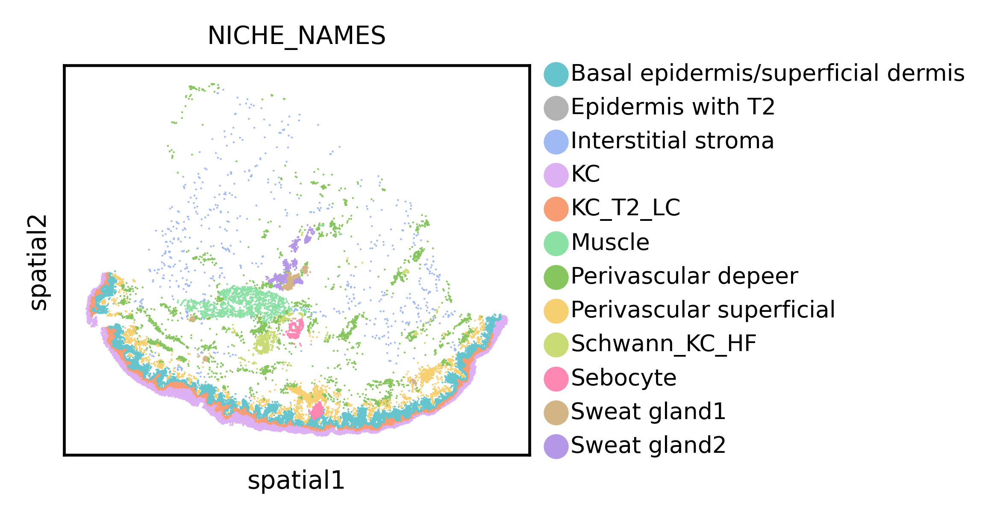

/tmp/ipykernel_4102485/2487453009.py:17: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'batch' as categorical


BK30_Lesional Baseline


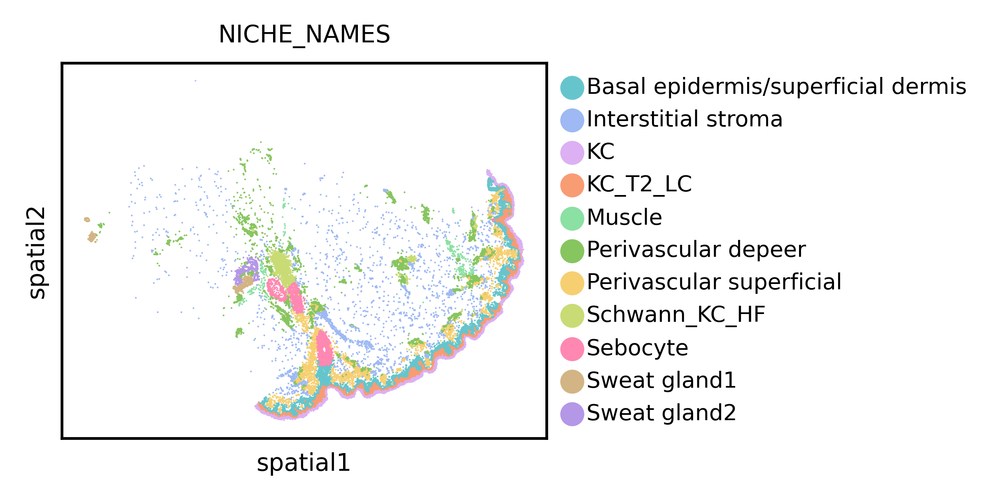

In [80]:
# Visualize ground truth niche labels in training samples
sample = list(set(adata_list[0].obs[sample_key].tolist()))[0]
batch = list(set(adata_list[0].obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_niche_label_transfer_ground_truth_niches.svg'
sc.pl.spatial(
    adata_list[0],
    color=niche_key,
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)

sample = list(set(adata_list[2].obs[sample_key].tolist()))[0]
batch = list(set(adata_list[2].obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_niche_label_transfer_ground_truth_niches.svg'
sc.pl.spatial(
    adata_list[2],
    color=niche_key,
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)

/tmp/ipykernel_4102485/345225140.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'batch' as categorical


BK39_Lesional Baseline


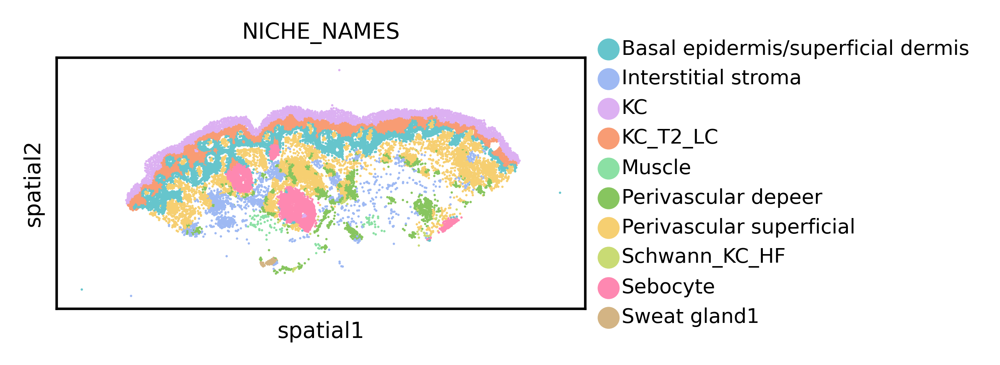

In [81]:
# Visualize ground truth niche labels in test sample
sample = list(set(adata_list[1].obs[sample_key].tolist()))[0]
batch = list(set(adata_list[1].obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_niche_label_transfer_ground_truth_niches.svg'
sc.pl.spatial(
    adata_list[1],
    color=niche_key,
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)

In [82]:
# Define cell type palette
cell_type_palette = {
    'KC4-5': '#1f78b4',
    'KC3': '#33a02c',
    'KC1': '#fb9a99',
    'Melanocyte': '#e31a1c',
    'KC2': '#a6cee3',
    'F2: Universal': '#fdbf6f',
    'Mac': '#b2df8a',
    'cDC2': '#cab2d6',
    'T': '#6a3d9a',
    'F3: TRC-like': '#ff7f00',
    'F2/3: Bridge': '#b15928',
    'T_GZMK+': '#ffff99',
    'F1: Superficial': '#8dd3c7',
    'VE/Pericyte': '#ffffb3',
    'cDC1': '#bebada',
    'LE': '#fb8072',
    'F5: Schwann-like': '#80b1d3',
    'Sweat gland channel outer': '#fdb462',
    'Sweat gland': '#b3de69',
    'F4: Mixed': '#fccde5',
    'Treg': '#d9d9d9',
    'Nonspecific': '#bc80bd',
    'Pre-adipocyte PPARG+ANGPTL8': '#ccebc5',
    'MigDC': '#ffed6f',
    'LC': '#a1dab4',
    'T_ITGAEhi_IL22': '#41b6c4',
    'T_vascular': '#2c7fb8',
    'Mast cell': '#253494',
    'Muscle': '#fed976',
    'KC_HF_Basal': '#e31a1c',
    'KC_HF_ORS': '#bd0026',
    'Sebocyte_CCL19': '#54278f',
    'Schwann': '#756bb1',
    'Sebocyte_PPARG': '#9e9ac8',
    'ILC2/Tnaive': '#6baed6',
    'F4: TNN+COCH+': '#4292c6',
    'pDC': '#2171b5',
    'KC_HF_inner': '#08519c',
    'LC/MigDC': '#08306b',
    'Plasma cell': '#ff66a1'
}

BK18_Lesional Baseline


/tmp/ipykernel_4102485/2358427716.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


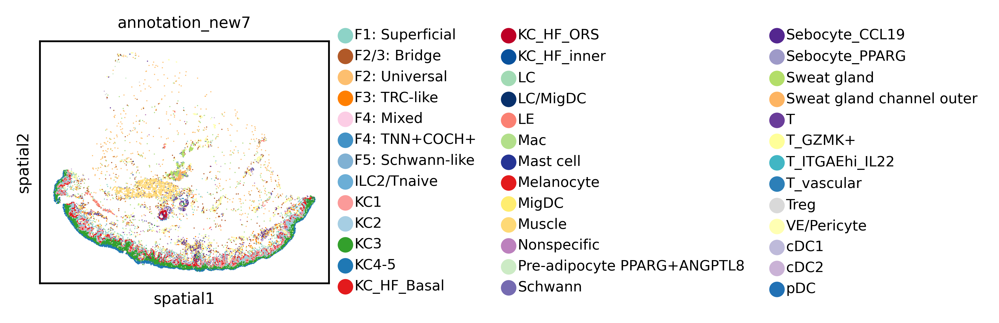

BK30_Lesional Baseline


/tmp/ipykernel_4102485/2358427716.py:17: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


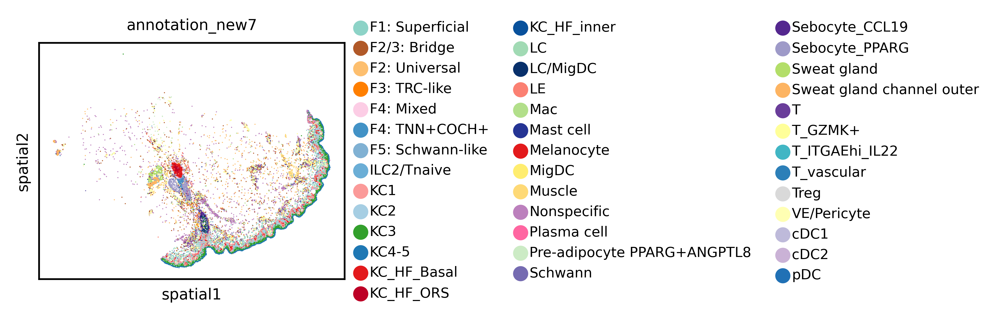

In [83]:
# Visualize ground truth cell type labels in training samples
sample = list(set(adata_list[0].obs[sample_key].tolist()))[0]
batch = list(set(adata_list[0].obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_cell_type_label_transfer_ground_truth_cell_types.svg'
sc.pl.spatial(
    adata_list[0],
    color=cell_type_key,
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)

sample = list(set(adata_list[2].obs[sample_key].tolist()))[0]
batch = list(set(adata_list[2].obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_cell_type_label_transfer_ground_truth_cell_types.svg'
sc.pl.spatial(
    adata_list[2],
    color=cell_type_key,
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)  

BK39_Lesional Baseline


/tmp/ipykernel_4102485/1730395663.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


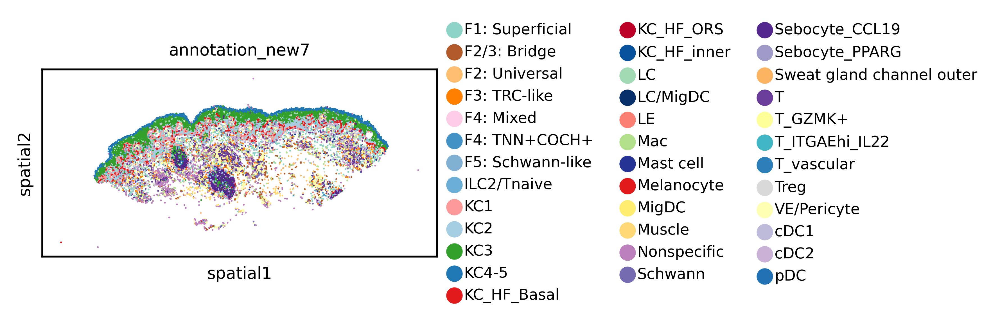

In [84]:
# Visualize ground truth cell type labels in test sample
sample = list(set(adata_list[1].obs[sample_key].tolist()))[0]
batch = list(set(adata_list[1].obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_cell_type_label_transfer_ground_truth_cell_types.svg'
sc.pl.spatial(
    adata_list[1],
    color=cell_type_key,
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)

### 2.1.2 NicheJEPA

In [100]:
method = 'NicheJEPA'
niche_key = 'niche_type'
emb_key = 'neighborhood_emb'

#### 2.1.2.1 Retrieve Embeddings

In [101]:
# Cell and neighborhood embeddings
adata_emb = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded_{model_timestamp}.h5ad')

In [103]:
# Gene embeddings
dataset_list = []

for file_path in file_paths:
    # Load tokenized AnnData or tokenize data
    dataset_path = f'{artifacts_folder_path}/{dataset_name}/{file_path.split("/")[-1].split(".")[0]}.dataset'
    if os.path.exists(dataset_path) and not force_retokenize:
        dataset = load_from_disk(dataset_path)
    else:
        # Tokenize AnnData
        dataset = tokenize_adata(
            adata,
            model_folder_path,
            cache_directory_path,
            nproc=nproc,
            processing_mode='parallel')

        # Save tokenized data
        os.makedirs(f'{artifacts_folder_path}/{dataset_name}', exist_ok=True)
        dataset.save_to_disk(
            dataset_path,
            num_shards=num_shards)

    dataset_list.append(dataset)

full_dataset = concatenate_datasets(dataset_list)

INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614/token_dictionary.pkl.


STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:663: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using generator for dataset creation.
Setting num_proc from 4 back to 1 for the train split to disable multiprocessing as it only contains one shard.
Generating train split: 18439 examples [00:05, 3385.98 examples/s]
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...
Map (num_proc=4): 100%|███████████| 18439/18439 [00:25<00:00, 711.99 examples/s]
Saving the dataset (32/32 shards): 100%|█| 18439/18439 [00:12<00:00, 1527.20 exa
INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614/token_dictionary.pkl.


STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:663: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using generator for dataset creation.
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...
Saving the dataset (32/32 shards): 100%|█| 18439/18439 [00:07<00:00, 2615.98 exa
INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614/token_dictionary.pkl.
/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:663: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.
Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using generator for dataset creation.
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...
Saving the dataset (32/32 shards): 100%|█| 18439/18439 [00:06<00:00, 2907.70 exa


#### 2.1.2.2 Train Niche Transfer Classifiers

In [25]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
print(cat_counts)
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

niche_type
Basal epidermis/superficial dermis    12668
Perivascular superficial               8740
KC_T2_LC                               7113
KC                                     6345
Perivascular depeer                    6265
Interstitial stroma                    3998
Sebocyte                               3656
Schwann_KC_HF                          1701
Muscle                                 1468
Sweat gland2                            858
Sweat gland1                            842
Epidermis with T2                         1
Name: count, dtype: int64


##### 2.1.2.2.1 Linear Classifier

In [26]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm[emb_key]

In [27]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = niche_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    niche_labels_train = niche_labels[train_indices]
    niche_labels_val = niche_labels[val_indices]
    niche_labels_test = niche_labels[test_indices]

    # Train and evaluate linear niche transfer classifier
    pred_niche_labels_test, _, _, model = linear_classifier(
        features_train=niche_features_train,
        labels_train=niche_labels_train,
        features_val=niche_features_val,
        labels_val=niche_labels_val,
        features_test=niche_features_test,
        labels_test=niche_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )
    
    #print(niche_categories[pred_niche_labels_test])

Using device: cuda
Epoch 1: Train Loss = 254.1719, Val Loss = 0.6321
Epoch 2: Train Loss = 141.6091, Val Loss = 0.4886
Epoch 3: Train Loss = 118.6452, Val Loss = 0.4261
Epoch 4: Train Loss = 105.9003, Val Loss = 0.3904
Epoch 5: Train Loss = 97.8994, Val Loss = 0.3665
Epoch 6: Train Loss = 93.3465, Val Loss = 0.3502
Epoch 7: Train Loss = 89.2211, Val Loss = 0.3377
Epoch 8: Train Loss = 86.2216, Val Loss = 0.3280
Epoch 9: Train Loss = 83.9462, Val Loss = 0.3197
Epoch 10: Train Loss = 81.9327, Val Loss = 0.3131
Epoch 11: Train Loss = 81.1003, Val Loss = 0.3074
Epoch 12: Train Loss = 79.8394, Val Loss = 0.3024
Epoch 13: Train Loss = 78.4501, Val Loss = 0.2991
Epoch 14: Train Loss = 76.8694, Val Loss = 0.2944
Epoch 15: Train Loss = 75.8628, Val Loss = 0.2909
Epoch 16: Train Loss = 74.9573, Val Loss = 0.2883
Epoch 17: Train Loss = 74.3677, Val Loss = 0.2850
Epoch 18: Train Loss = 73.9347, Val Loss = 0.2823
Epoch 19: Train Loss = 72.8225, Val Loss = 0.2803
Epoch 20: Train Loss = 72.2811, Val 

In [28]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

/tmp/ipykernel_4102485/2067894836.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'niche_type_pred_linear' as categorical


BK39_Lesional Baseline


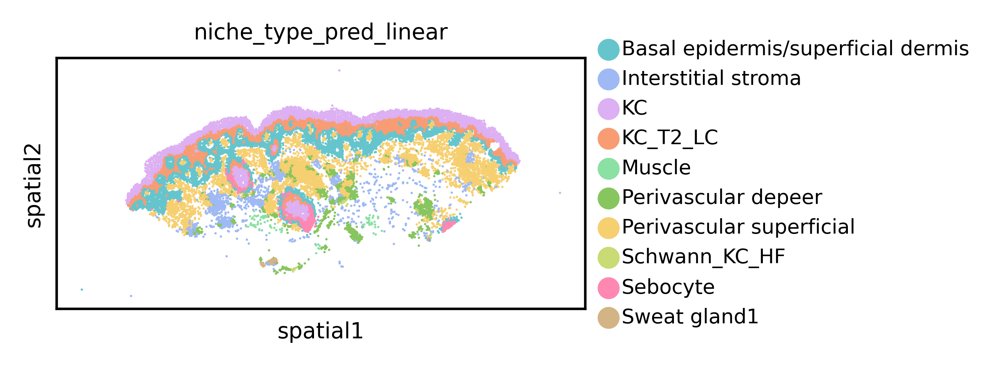

In [29]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_{model_timestamp}_niche_label_transfer_linear_classifer_predicted_niches_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.2.2.2 KNN Classifier

In [30]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [31]:
# Train and evaluate knn niche transfer classifier
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_niche_label_transfer_knn_cls_report.txt')

Using device: cuda

--- Evaluation Report on Test Set ---
              precision    recall  f1-score   support

           0     0.7824    0.9283    0.8491      3865
           1     0.8853    0.8076    0.8447      1185
           2     0.8212    0.8830    0.8510      2008
           3     0.6308    0.8033    0.7067      2578
           4     0.9620    0.8736    0.9157        87
           5     0.7810    0.7142    0.7461      1298
           6     0.8956    0.9256    0.9103      4421
           7     0.6944    0.4386    0.5376        57
           8     0.5989    0.1197    0.1995      1821
           9     1.0000    0.6250    0.7692        64

    accuracy                         0.7919     17384
   macro avg     0.8052    0.7119    0.7330     17384
weighted avg     0.7823    0.7919    0.7668     17384


--- Evaluation Report saved. ---


In [32]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

/tmp/ipykernel_4102485/4254071233.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'niche_type_pred_knn' as categorical


BK39_Lesional Baseline


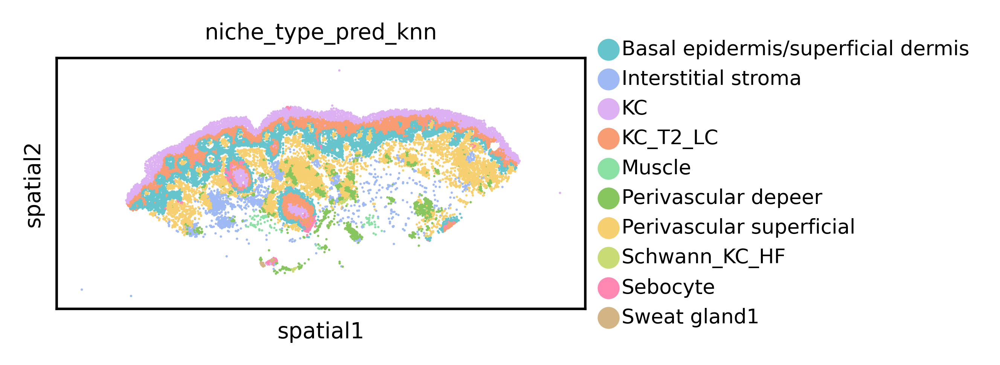

In [33]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_{model_timestamp}_niche_label_transfer_knn_classifer_predicted_niches.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.2.3 Train Cell Type Transfer Classifiers

In [34]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

##### 2.1.2.3.1 Linear Classifier

In [35]:
# Retrieve features and labels
cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm['cell_emb']

In [36]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    cell_type_features_train = cell_type_features[train_indices]
    cell_type_features_val = cell_type_features[val_indices]
    cell_type_features_test = cell_type_features[test_indices]
    cell_type_labels_train = cell_type_labels[train_indices]
    cell_type_labels_val = cell_type_labels[val_indices]
    cell_type_labels_test = cell_type_labels[test_indices]

    # Train and evaluate linear cell type transfer classifier
    pred_cell_type_labels_test, _, _, model = linear_classifier(
        features_train=cell_type_features_train,
        labels_train=cell_type_labels_train,
        features_val=cell_type_features_val,
        labels_val=cell_type_labels_val,
        features_test=cell_type_features_test,
        labels_test=cell_type_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )

    #print(cell_type_categories[pred_cell_type_labels_test])

Using device: cuda
Epoch 1: Train Loss = 545.4523, Val Loss = 1.5981
Epoch 2: Train Loss = 371.5615, Val Loss = 1.3339
Epoch 3: Train Loss = 324.6472, Val Loss = 1.2051
Epoch 4: Train Loss = 297.3169, Val Loss = 1.1238
Epoch 5: Train Loss = 280.4669, Val Loss = 1.0675
Epoch 6: Train Loss = 268.5995, Val Loss = 1.0258
Epoch 7: Train Loss = 259.3828, Val Loss = 0.9932
Epoch 8: Train Loss = 251.8438, Val Loss = 0.9677
Epoch 9: Train Loss = 245.3092, Val Loss = 0.9453
Epoch 10: Train Loss = 241.8530, Val Loss = 0.9267
Epoch 11: Train Loss = 235.8172, Val Loss = 0.9115
Epoch 12: Train Loss = 233.5892, Val Loss = 0.8968
Epoch 13: Train Loss = 228.0495, Val Loss = 0.8847
Epoch 14: Train Loss = 225.2575, Val Loss = 0.8727
Epoch 15: Train Loss = 222.7061, Val Loss = 0.8630
Epoch 16: Train Loss = 219.6929, Val Loss = 0.8545
Epoch 17: Train Loss = 218.9651, Val Loss = 0.8461
Epoch 18: Train Loss = 216.2254, Val Loss = 0.8386
Epoch 19: Train Loss = 214.3575, Val Loss = 0.8316
Epoch 20: Train Loss 

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capit

Epoch 1: Train Loss = 542.3412, Val Loss = 1.5938
Epoch 2: Train Loss = 371.6289, Val Loss = 1.3324
Epoch 3: Train Loss = 323.3574, Val Loss = 1.2048
Epoch 4: Train Loss = 297.3323, Val Loss = 1.1245
Epoch 5: Train Loss = 281.2011, Val Loss = 1.0684
Epoch 6: Train Loss = 268.3315, Val Loss = 1.0275
Epoch 7: Train Loss = 258.7181, Val Loss = 0.9952
Epoch 8: Train Loss = 251.9255, Val Loss = 0.9695
Epoch 9: Train Loss = 244.4757, Val Loss = 0.9480
Epoch 10: Train Loss = 239.3822, Val Loss = 0.9308
Epoch 11: Train Loss = 235.0747, Val Loss = 0.9151
Epoch 12: Train Loss = 231.1228, Val Loss = 0.9021
Epoch 13: Train Loss = 228.3487, Val Loss = 0.8895
Epoch 14: Train Loss = 225.5936, Val Loss = 0.8795
Epoch 15: Train Loss = 222.4967, Val Loss = 0.8693
Epoch 16: Train Loss = 220.0819, Val Loss = 0.8607
Epoch 17: Train Loss = 219.7562, Val Loss = 0.8535
Epoch 18: Train Loss = 216.7050, Val Loss = 0.8461
Epoch 19: Train Loss = 213.7603, Val Loss = 0.8398
Epoch 20: Train Loss = 211.6843, Val Los

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capit

Epoch 1: Train Loss = 539.9387, Val Loss = 1.6024
Epoch 2: Train Loss = 371.3997, Val Loss = 1.3364
Epoch 3: Train Loss = 324.7317, Val Loss = 1.2047
Epoch 4: Train Loss = 298.2418, Val Loss = 1.1224
Epoch 5: Train Loss = 280.8734, Val Loss = 1.0657
Epoch 6: Train Loss = 268.8131, Val Loss = 1.0237
Epoch 7: Train Loss = 259.6703, Val Loss = 0.9902
Epoch 8: Train Loss = 252.5376, Val Loss = 0.9637
Epoch 9: Train Loss = 246.1950, Val Loss = 0.9420
Epoch 10: Train Loss = 240.4872, Val Loss = 0.9230
Epoch 11: Train Loss = 236.7646, Val Loss = 0.9066
Epoch 12: Train Loss = 232.5022, Val Loss = 0.8926
Epoch 13: Train Loss = 228.5265, Val Loss = 0.8809
Epoch 14: Train Loss = 226.3427, Val Loss = 0.8702
Epoch 15: Train Loss = 223.4084, Val Loss = 0.8598
Epoch 16: Train Loss = 220.6926, Val Loss = 0.8499
Epoch 17: Train Loss = 218.3867, Val Loss = 0.8419
Epoch 18: Train Loss = 216.3593, Val Loss = 0.8347
Epoch 19: Train Loss = 214.7491, Val Loss = 0.8282
Epoch 20: Train Loss = 213.8424, Val Los

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capit

... (6 outputs left out)

Epoch 1: Train Loss = 542.3102, Val Loss = 1.6227
Epoch 2: Train Loss = 369.7436, Val Loss = 1.3610
Epoch 3: Train Loss = 323.8221, Val Loss = 1.2332
Epoch 4: Train Loss = 296.7680, Val Loss = 1.1539
Epoch 5: Train Loss = 280.6789, Val Loss = 1.0990
Epoch 6: Train Loss = 267.2830, Val Loss = 1.0578
Epoch 7: Train Loss = 257.6077, Val Loss = 1.0260
Epoch 8: Train Loss = 250.5345, Val Loss = 1.0008
Epoch 9: Train Loss = 244.5999, Val Loss = 0.9787
Epoch 10: Train Loss = 240.6903, Val Loss = 0.9617
Epoch 11: Train Loss = 234.4520, Val Loss = 0.9449
Epoch 12: Train Loss = 231.3881, Val Loss = 0.9315
Epoch 13: Train Loss = 229.4046, Val Loss = 0.9192
Epoch 14: Train Loss = 224.7746, Val Loss = 0.9080
Epoch 15: Train Loss = 222.9250, Val Loss = 0.8988
Epoch 16: Train Loss = 219.5567, Val Loss = 0.8895
Epoch 17: Train Loss = 217.9857, Val Loss = 0.8817
Epoch 18: Train Loss = 215.1765, Val Loss = 0.8739
Epoch 19: Train Loss = 213.1727, Val Loss = 0.8671
Epoch 20: Train Loss = 212.4108, Val Los

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capit


--- Evaluation Report saved. ---
Using device: cuda
Epoch 1: Train Loss = 543.3142, Val Loss = 1.6047
Epoch 2: Train Loss = 371.6328, Val Loss = 1.3408
Epoch 3: Train Loss = 324.6417, Val Loss = 1.2137
Epoch 4: Train Loss = 298.6778, Val Loss = 1.1345
Epoch 5: Train Loss = 282.0483, Val Loss = 1.0799
Epoch 6: Train Loss = 269.3024, Val Loss = 1.0391
Epoch 7: Train Loss = 259.1370, Val Loss = 1.0090
Epoch 8: Train Loss = 250.7800, Val Loss = 0.9829
Epoch 9: Train Loss = 245.6706, Val Loss = 0.9624
Epoch 10: Train Loss = 240.1464, Val Loss = 0.9436
Epoch 11: Train Loss = 236.5172, Val Loss = 0.9287
Epoch 12: Train Loss = 231.6046, Val Loss = 0.9155
Epoch 13: Train Loss = 228.0365, Val Loss = 0.9044
Epoch 14: Train Loss = 226.0179, Val Loss = 0.8936
Epoch 15: Train Loss = 221.9244, Val Loss = 0.8865
Epoch 16: Train Loss = 219.9793, Val Loss = 0.8756
Epoch 17: Train Loss = 218.0299, Val Loss = 0.8683
Epoch 18: Train Loss = 215.7669, Val Loss = 0.8605
Epoch 19: Train Loss = 212.9991, Val L

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capit

In [37]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{cell_type_key}_pred_linear'] = cell_type_categories[pred_cell_type_labels_test]

/tmp/ipykernel_4102485/640755181.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'annotation_new7_pred_linear' as categorical


BK39_Lesional Baseline


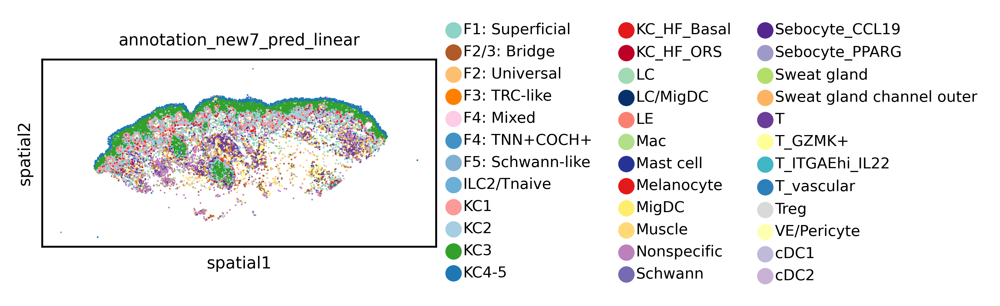

In [38]:
# Visualize predicted cell type labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_{model_timestamp}_cell_type_label_transfer_linear_classifer_predicted_cell_types_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_linear',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.2.3.2 KNN Classifier

In [39]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [40]:
# Train and evaluate knn cell type transfer classifier
pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_cell_type_label_transfer_knn_cls_report.txt')

Using device: cuda

--- Evaluation Report on Test Set ---
              precision    recall  f1-score   support

           0     0.6847    0.8386    0.7539       725
           1     0.4485    0.4296    0.4388       284
           2     0.5263    0.7299    0.6116       137
           3     0.6176    0.6346    0.6260       509
           4     0.0000    0.0000    0.0000        14
           5     0.0000    0.0000    0.0000         8
           6     0.0000    0.0000    0.0000         8
           7     0.0000    0.0000    0.0000        75
           8     0.5524    0.8465    0.6686      1388
           9     0.6345    0.7381    0.6824      2039
          10     0.6936    0.8600    0.7679      2608
          11     0.8950    0.8893    0.8922       786
          12     0.0000    0.0000    0.0000         4
          13     0.0000    0.0000    0.0000        11
          14     0.0000    0.0000    0.0000         1
          15     0.2794    0.3333    0.3040       285
          16     0.0476

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metr

In [41]:
# Store predictions
adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

/tmp/ipykernel_4102485/1195310336.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'annotation_new7_pred_knn' as categorical


BK39_Lesional Baseline


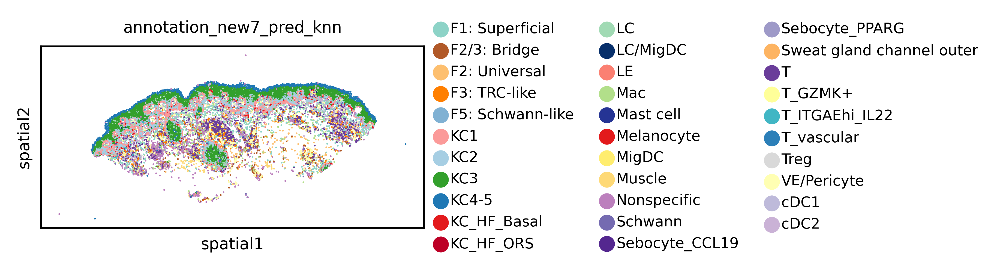

In [42]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_{model_timestamp}_cell_type_label_transfer_knn_classifer_predicted_cell_types.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.2.4 Train Neighborhood Composition Classifiers

In [ ]:
# Compute spatial neighborhood graph
adata_batch_list = []
batches = adata_emb.obs[batch_key].unique().tolist()

for batch in batches:
    adata_batch = adata_emb[adata_emb.obs[batch_key] == batch]
    print('Computing spatial neighborhood...')
    # Construct neighbor graph
    adata_batch = construct_neighbor_graph(
        adata_batch,
        n_neighs=n_neighs,
        radius=None,
        delaunay=None,
        include_self_loop=False,
        compute_neighbor_counts=False)
    adata_batch_list.append(adata_batch)

adata_combined = sc.concat(adata_batch_list, join="inner")

# Combine spatial neighborhood graphs as disconnected components
batch_connectivities = []
len_before_batch = 0
for i in range(len(adata_batch_list)):
    if i == 0: # first batch
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[0].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[0].shape[0])))
        batch_connectivities.append(sp.hstack(
            (adata_batch_list[0].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    elif i == (len(adata_batch_list) - 1): # last batch
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0])))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'])))
    else: # middle batches
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0], len_before_batch))
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0] -
            len_before_batch)))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    len_before_batch += adata_batch_list[i].shape[0]
connectivities = sp.vstack(batch_connectivities)
adata_combined.obsp['spatial_connectivities'] = connectivities

composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
cell_type_composition_labels = composition_df.values
niche_features = adata_emb.obsm['neighborhood_emb']

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get neighborhood composition labels and features
    composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
    cell_type_composition_labels = composition_df.values
    niche_features = adata_emb.obsm['neighborhood_emb']
    
    # Get train and validation indices
    train_val_indices = (adata_emb.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_composition_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        #stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_emb.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
    cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
    cell_type_composition_labels_test = cell_type_composition_labels[test_indices]
    
    pred_cell_type_composition_labels, model = linear_regressor(
        features_train=niche_features_train,
        labels_train=cell_type_composition_labels_train,
        features_val=niche_features_val,
        labels_val=cell_type_composition_labels_val,
        features_test=niche_features_test,
        labels_test=cell_type_composition_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_neighborhood_composition_linear_classifier_cls_report_seed_{seed}.txt'
    )
    
    print(pred_cell_type_composition_labels)

#### 2.1.2.5 Ligand-Receptor Prediction

##### 2.1.2.5.1 CellPhoneDB

In [110]:
lr_database = 'cellphonedb'

In [111]:
# Get Ensembl IDs
adata_emb.var = adata_list[0].var

In [112]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata_emb,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata_emb,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')

# Randomly shuffle rows
lr_interaction_df = lr_interaction_df.sample(
    frac=1, random_state=0).reset_index(drop=True)

print(lr_interaction_df)

Downloaded cellphonedb.zip into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded complex_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded gene_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded interaction_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded protein_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0
Downloaded uniprot_synonyms.tsv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/sources
Downloaded transcription_factor_input.csv into /nfs/team361/sb75/nichejepa-reproducibility/artifacts/cellphonedb/v5.0.0/sources

              ligand         receptor
0    ENSG00000112715  ENSG00000128052
1    ENSG00000111144  ENSG00000144230
2    ENSG00000141433  ENSG00000114812
3    ENSG00000226979  ENSG00000028137
4    ENSG00000241563  ENSG000

In [113]:
from pathlib import Path
import pickle

# Load token dictionary
token_dictionary_file_path = Path(model_folder_path) / 'token_dictionary.pkl'
with open(token_dictionary_file_path, 'rb') as f:
    token_dict = pickle.load(f)

neighborhood_gene_ids = [token_dict[ensg] for ensg in neighborhood_gene_ensembl_id]
cell_gene_ids         = [token_dict[ensg] for ensg in cell_gene_ensembl_id]

In [129]:
17416 in list(set(cell_gene_ids))

True

In [126]:
token_dict_reverse

NameError: name 'token_dict_reverse' is not defined

In [124]:
token_dict[17416]

KeyError: 17415

In [127]:
model_folder_path

'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614'

In [137]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_gene_embed_{lr_database}.pkl'

if os.path.exists(file_path):
    with open(file_path, "rb") as f:
        output_gene_embed = pickle.load(f)
else:
    cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
    neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()
    
    output_gene_embed = get_gene_embed(
        dataset=full_dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers,
        cell_gene_ensembl_id=cell_gene_ensembl_id,
        neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
    )
    
    with open(file_path, "wb") as f:
        pickle.dump(output_gene_embed, f) # shape (414, 384)

STEP 1: LOADING CONFIG...
STEP 2: GETTING GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
    (pos_embed): Embedding(2817, 384, padd

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:1659: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
1it [00:01,  1.78s/it]

YAAASES


2it [00:02,  1.28s/it]

... (859 outputs left out)

433it [06:51,  1.41it/s]

YAAASES


433it [06:53,  1.05it/s]


KeyError: 17416

In [ ]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_average_gene_embed_{lr_database}.pkl'

if os.path.exists(file_path):
    with open(file_path, "rb") as f:
        output_average_gene_embed = pickle.load(f)
else:
    cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
    neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()
    
    output_average_gene_embed = get_average_gene_embed(
        dataset=full_dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers,
        cell_gene_ensembl_id=cell_gene_ensembl_id,
        neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
    )
    
    with open(file_path, "wb") as f:
        pickle.dump(output_average_gene_embed, f) # shape (414, 384)

In [ ]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

### Use second half of ligand-receptor pairs as negative pairs ###
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    train_ratio = 0.8
    test_ratio = 0.1
    val_ratio = 0.1
    
    # --- Splitting using sklearn ---
    # First, split off the test set
    ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
        ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)
    
    # Then split the remaining temp set into train and val
    # The new val ratio is relative to the remaining data
    val_relative_ratio = val_ratio / (train_ratio + val_ratio)
    
    ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
        ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)
    
    # Train and evaluate linear ligand-receptor classifier
    pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
        features_train=ligand_receptor_features_train,
        labels_train=ligand_receptor_labels_train,
        features_val=ligand_receptor_features_val,
        labels_val=ligand_receptor_labels_val,
        features_test=ligand_receptor_features_test,
        labels_test=ligand_receptor_labels_test,
        n_epochs=500,
        batch_size=16,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_cls_report_seed_{seed}.txt'
        )

    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_pred_lr_labels_seed_{seed}.txt', "wb") as f:
        pickle.dump(pred_lr_labels, f)
    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_lr_labels_seed_{seed}.txt', "wb") as f:
        pickle.dump(lr_labels, f)
    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_lr_logits_seed_{seed}.txt', "wb") as f:
        pickle.dump(lr_logits, f)

##### 2.1.2.5.2 OmniPath

In [ ]:
lr_database = 'omnipath'

In [ ]:
# Get Ensembl IDs
adata_emb.var = adata_list[0].var

In [ ]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata_emb,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata_emb,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')
print(lr_interaction_df)

# Randomly shuffle rows
lr_interaction_df = lr_interaction_df.sample(
    frac=1, random_state=0).reset_index(drop=True)

In [ ]:
lr_interaction_df

In [ ]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_average_gene_embed_{lr_database}.pkl'

if os.path.exists(file_path):
    with open(file_path, "rb") as f:
        output_average_gene_embed = pickle.load(f)
else:
    cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
    neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()
    
    output_average_gene_embed = get_average_gene_embed(
        dataset=full_dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers,
        cell_gene_ensembl_id=cell_gene_ensembl_id,
        neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
    )
    
    with open(file_path, "wb") as f:
        pickle.dump(output_average_gene_embed, f) # shape (1159, 384)

In [ ]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

### Use second half of ligand-receptor pairs as negative pairs ###
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    train_ratio = 0.8
    test_ratio = 0.1
    val_ratio = 0.1
    
    # --- Splitting using sklearn ---
    # First, split off the test set
    ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
        ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)
    
    # Then split the remaining temp set into train and val
    # The new val ratio is relative to the remaining data
    val_relative_ratio = val_ratio / (train_ratio + val_ratio)
    
    ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
        ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)
    
    # Train and evaluate linear ligand-receptor classifier
    pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
        features_train=ligand_receptor_features_train,
        labels_train=ligand_receptor_labels_train,
        features_val=ligand_receptor_features_val,
        labels_val=ligand_receptor_labels_val,
        features_test=ligand_receptor_features_test,
        labels_test=ligand_receptor_labels_test,
        n_epochs=500,
        batch_size=16,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_cls_report_seed_{seed}.txt'
        )

    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_pred_lr_labels_seed_{seed}.txt', "wb") as f:
        pickle.dump(pred_lr_labels, f)
    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_lr_labels_seed_{seed}.txt', "wb") as f:
        pickle.dump(lr_labels, f)
    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_lr_logits_seed_{seed}.txt', "wb") as f:
        pickle.dump(lr_logits, f)

### 2.1.3 CellPLM

In [ ]:
method = 'CellPLM'
niche_key = 'niche_type'
emb_key = 'emb'

#### 2.1.3.1 Retrieve Embeddings

In [ ]:
# Cell embeddings
adata_emb = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

#### 2.1.3.2 Train Niche Transfer Classifiers

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
print(cat_counts)
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

##### 2.1.3.2.1 Linear Classifier

In [ ]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = niche_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    niche_labels_train = niche_labels[train_indices]
    niche_labels_val = niche_labels[val_indices]
    niche_labels_test = niche_labels[test_indices]

    # Train and evaluate linear niche transfer classifier
    pred_niche_labels_test, _, _, model = linear_classifier(
        features_train=niche_features_train,
        labels_train=niche_labels_train,
        features_val=niche_features_val,
        labels_val=niche_labels_val,
        features_test=niche_features_test,
        labels_test=niche_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )
    
    #print(niche_categories[pred_niche_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_niche_label_transfer_linear_classifer_predicted_niches_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.3.2.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [ ]:
# Train and evaluate knn niche transfer classifier
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_niche_label_transfer_knn_classifer_predicted_niches.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.3.3 Train Cell Type Transfer Classifiers

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

##### 2.1.3.3.1 Linear Classifier

In [ ]:
# Retrieve features and labels
cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    cell_type_features_train = cell_type_features[train_indices]
    cell_type_features_val = cell_type_features[val_indices]
    cell_type_features_test = cell_type_features[test_indices]
    cell_type_labels_train = cell_type_labels[train_indices]
    cell_type_labels_val = cell_type_labels[val_indices]
    cell_type_labels_test = cell_type_labels[test_indices]

    # Train and evaluate linear cell type transfer classifier
    pred_cell_type_labels_test, _, _, model = linear_classifier(
        features_train=cell_type_features_train,
        labels_train=cell_type_labels_train,
        features_val=cell_type_features_val,
        labels_val=cell_type_labels_val,
        features_test=cell_type_features_test,
        labels_test=cell_type_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )

    #print(cell_type_categories[pred_cell_type_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{cell_type_key}_pred_linear'] = cell_type_categories[pred_cell_type_labels_test]

In [ ]:
# Visualize predicted cell type labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_cell_type_label_transfer_linear_classifer_predicted_cell_types_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_linear',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.3.3.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [ ]:
# Train and evaluate knn cell type transfer classifier
pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_cell_type_label_transfer_knn_classifer_predicted_cell_types.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.3.4 Train Neighborhood Composition Classifiers

In [ ]:
# Compute spatial neighborhood graph
adata_batch_list = []
batches = adata_emb.obs[batch_key].unique().tolist()

for batch in batches:
    adata_batch = adata_emb[adata_emb.obs[batch_key] == batch]
    print('Computing spatial neighborhood...')
    # Construct neighbor graph
    adata_batch = construct_neighbor_graph(
        adata_batch,
        n_neighs=n_neighs,
        radius=None,
        delaunay=None,
        include_self_loop=False,
        compute_neighbor_counts=False)
    adata_batch_list.append(adata_batch)

adata_combined = sc.concat(adata_batch_list, join="inner")

# Combine spatial neighborhood graphs as disconnected components
batch_connectivities = []
len_before_batch = 0
for i in range(len(adata_batch_list)):
    if i == 0: # first batch
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[0].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[0].shape[0])))
        batch_connectivities.append(sp.hstack(
            (adata_batch_list[0].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    elif i == (len(adata_batch_list) - 1): # last batch
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0])))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'])))
    else: # middle batches
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0], len_before_batch))
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0] -
            len_before_batch)))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    len_before_batch += adata_batch_list[i].shape[0]
connectivities = sp.vstack(batch_connectivities)
adata_combined.obsp['spatial_connectivities'] = connectivities

composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
cell_type_composition_labels = composition_df.values
niche_features = adata_emb.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get neighborhood composition labels and features
    composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
    cell_type_composition_labels = composition_df.values
    niche_features = adata_emb.obsm[emb_key]
    
    # Get train and validation indices
    train_val_indices = (adata_emb.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_composition_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        #stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_emb.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
    cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
    cell_type_composition_labels_test = cell_type_composition_labels[test_indices]
    
    pred_cell_type_composition_labels, model = linear_regressor(
        features_train=niche_features_train,
        labels_train=cell_type_composition_labels_train,
        features_val=niche_features_val,
        labels_val=cell_type_composition_labels_val,
        features_test=niche_features_test,
        labels_test=cell_type_composition_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_neighborhood_composition_linear_classifier_cls_report_seed_{seed}.txt'
    )
    
    print(pred_cell_type_composition_labels)

### 2.1.4 Nicheformer

In [ ]:
method = 'nicheformer'
niche_key = 'niche_type'
emb_key = 'X_niche_embeddings'

#### 2.1.4.1 Retrieve Embeddings

In [ ]:
# Cell embeddings
adata_emb = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

#### 2.1.4.2 Train Niche Transfer Classifiers

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
print(cat_counts)
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

##### 2.1.4.2.1 Linear Classifier

In [ ]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = niche_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    niche_labels_train = niche_labels[train_indices]
    niche_labels_val = niche_labels[val_indices]
    niche_labels_test = niche_labels[test_indices]

    # Train and evaluate linear niche transfer classifier
    pred_niche_labels_test, _, _, model = linear_classifier(
        features_train=niche_features_train,
        labels_train=niche_labels_train,
        features_val=niche_features_val,
        labels_val=niche_labels_val,
        features_test=niche_features_test,
        labels_test=niche_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )
    
    #print(niche_categories[pred_niche_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_niche_label_transfer_linear_classifer_predicted_niches_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.4.2.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [ ]:
# Train and evaluate knn niche transfer classifier
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_niche_label_transfer_knn_classifer_predicted_niches.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.4.3 Train Cell Type Transfer Classifiers

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

##### 2.1.4.3.1 Linear Classifier

In [ ]:
# Retrieve features and labels
cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    cell_type_features_train = cell_type_features[train_indices]
    cell_type_features_val = cell_type_features[val_indices]
    cell_type_features_test = cell_type_features[test_indices]
    cell_type_labels_train = cell_type_labels[train_indices]
    cell_type_labels_val = cell_type_labels[val_indices]
    cell_type_labels_test = cell_type_labels[test_indices]

    # Train and evaluate linear cell type transfer classifier
    pred_cell_type_labels_test, _, _, model = linear_classifier(
        features_train=cell_type_features_train,
        labels_train=cell_type_labels_train,
        features_val=cell_type_features_val,
        labels_val=cell_type_labels_val,
        features_test=cell_type_features_test,
        labels_test=cell_type_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )

    #print(cell_type_categories[pred_cell_type_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{cell_type_key}_pred_linear'] = cell_type_categories[pred_cell_type_labels_test]

In [ ]:
# Visualize predicted cell type labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_cell_type_label_transfer_linear_classifer_predicted_cell_types_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_linear',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.4.3.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [ ]:
# Train and evaluate knn cell type transfer classifier
pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_cell_type_label_transfer_knn_classifer_predicted_cell_types.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.4.4 Train Neighborhood Composition Classifiers

In [ ]:
# Compute spatial neighborhood graph
adata_batch_list = []
batches = adata_emb.obs[batch_key].unique().tolist()

for batch in batches:
    adata_batch = adata_emb[adata_emb.obs[batch_key] == batch]
    print('Computing spatial neighborhood...')
    # Construct neighbor graph
    adata_batch = construct_neighbor_graph(
        adata_batch,
        n_neighs=n_neighs,
        radius=None,
        delaunay=None,
        include_self_loop=False,
        compute_neighbor_counts=False)
    adata_batch_list.append(adata_batch)

adata_combined = sc.concat(adata_batch_list, join="inner")

# Combine spatial neighborhood graphs as disconnected components
batch_connectivities = []
len_before_batch = 0
for i in range(len(adata_batch_list)):
    if i == 0: # first batch
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[0].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[0].shape[0])))
        batch_connectivities.append(sp.hstack(
            (adata_batch_list[0].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    elif i == (len(adata_batch_list) - 1): # last batch
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0])))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'])))
    else: # middle batches
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0], len_before_batch))
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0] -
            len_before_batch)))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    len_before_batch += adata_batch_list[i].shape[0]
connectivities = sp.vstack(batch_connectivities)
adata_combined.obsp['spatial_connectivities'] = connectivities

composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
cell_type_composition_labels = composition_df.values
niche_features = adata_emb.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get neighborhood composition labels and features
    composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
    cell_type_composition_labels = composition_df.values
    niche_features = adata_emb.obsm[emb_key]
    
    # Get train and validation indices
    train_val_indices = (adata_emb.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_composition_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        #stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_emb.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
    cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
    cell_type_composition_labels_test = cell_type_composition_labels[test_indices]
    
    pred_cell_type_composition_labels, model = linear_regressor(
        features_train=niche_features_train,
        labels_train=cell_type_composition_labels_train,
        features_val=niche_features_val,
        labels_val=cell_type_composition_labels_val,
        features_test=niche_features_test,
        labels_test=cell_type_composition_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_neighborhood_composition_linear_classifier_cls_report_seed_{seed}.txt'
    )
    
    print(pred_cell_type_composition_labels)

### 2.1.5 Novae

In [ ]:
method = 'Novae'
niche_key = 'niche_type'
emb_key = 'novae_latent'

#### 2.1.5.1 Retrieve Embeddings

In [ ]:
# Cell embeddings
adata_emb = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

#### 2.1.5.2 Train Niche Transfer Classifiers

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
print(cat_counts)
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

##### 2.1.5.2.1 Linear Classifier

In [ ]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = niche_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    niche_labels_train = niche_labels[train_indices]
    niche_labels_val = niche_labels[val_indices]
    niche_labels_test = niche_labels[test_indices]

    # Train and evaluate linear niche transfer classifier
    pred_niche_labels_test, _, _, model = linear_classifier(
        features_train=niche_features_train,
        labels_train=niche_labels_train,
        features_val=niche_features_val,
        labels_val=niche_labels_val,
        features_test=niche_features_test,
        labels_test=niche_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )
    
    #print(niche_categories[pred_niche_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_niche_label_transfer_linear_classifer_predicted_niches_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.5.2.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [ ]:
# Train and evaluate knn niche transfer classifier
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_niche_label_transfer_knn_classifer_predicted_niches.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.5.3 Train Cell Type Transfer Classifiers

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

##### 2.1.5.3.1 Linear Classifier

In [ ]:
# Retrieve features and labels
cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    cell_type_features_train = cell_type_features[train_indices]
    cell_type_features_val = cell_type_features[val_indices]
    cell_type_features_test = cell_type_features[test_indices]
    cell_type_labels_train = cell_type_labels[train_indices]
    cell_type_labels_val = cell_type_labels[val_indices]
    cell_type_labels_test = cell_type_labels[test_indices]

    # Train and evaluate linear cell type transfer classifier
    pred_cell_type_labels_test, _, _, model = linear_classifier(
        features_train=cell_type_features_train,
        labels_train=cell_type_labels_train,
        features_val=cell_type_features_val,
        labels_val=cell_type_labels_val,
        features_test=cell_type_features_test,
        labels_test=cell_type_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )

    #print(cell_type_categories[pred_cell_type_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{cell_type_key}_pred_linear'] = cell_type_categories[pred_cell_type_labels_test]

In [ ]:
# Visualize predicted cell type labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_cell_type_label_transfer_linear_classifer_predicted_cell_types_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_linear',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.5.3.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [ ]:
# Train and evaluate knn cell type transfer classifier
pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_cell_type_label_transfer_knn_classifer_predicted_cell_types.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.5.4 Train Neighborhood Composition Classifiers

In [ ]:
# Compute spatial neighborhood graph
adata_batch_list = []
batches = adata_emb.obs[batch_key].unique().tolist()

for batch in batches:
    adata_batch = adata_emb[adata_emb.obs[batch_key] == batch]
    print('Computing spatial neighborhood...')
    # Construct neighbor graph
    adata_batch = construct_neighbor_graph(
        adata_batch,
        n_neighs=n_neighs,
        radius=None,
        delaunay=None,
        include_self_loop=False,
        compute_neighbor_counts=False)
    adata_batch_list.append(adata_batch)

adata_combined = sc.concat(adata_batch_list, join="inner")

# Combine spatial neighborhood graphs as disconnected components
batch_connectivities = []
len_before_batch = 0
for i in range(len(adata_batch_list)):
    if i == 0: # first batch
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[0].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[0].shape[0])))
        batch_connectivities.append(sp.hstack(
            (adata_batch_list[0].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    elif i == (len(adata_batch_list) - 1): # last batch
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0])))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'])))
    else: # middle batches
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0], len_before_batch))
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0] -
            len_before_batch)))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    len_before_batch += adata_batch_list[i].shape[0]
connectivities = sp.vstack(batch_connectivities)
adata_combined.obsp['spatial_connectivities'] = connectivities

composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
cell_type_composition_labels = composition_df.values
niche_features = adata_emb.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get neighborhood composition labels and features
    composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
    cell_type_composition_labels = composition_df.values
    niche_features = adata_emb.obsm[emb_key]
    
    # Get train and validation indices
    train_val_indices = (adata_emb.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_composition_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        #stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_emb.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
    cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
    cell_type_composition_labels_test = cell_type_composition_labels[test_indices]
    
    pred_cell_type_composition_labels, model = linear_regressor(
        features_train=niche_features_train,
        labels_train=cell_type_composition_labels_train,
        features_val=niche_features_val,
        labels_val=cell_type_composition_labels_val,
        features_test=niche_features_test,
        labels_test=cell_type_composition_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_neighborhood_composition_linear_classifier_cls_report_seed_{seed}.txt'
    )
    
    print(pred_cell_type_composition_labels)

### 2.1.6 scGPT-spatial

In [ ]:
method = 'scGPT-spatial'
niche_key = 'niche_type'
emb_key = 'X'

#### 2.1.6.1 Retrieve Embeddings

In [ ]:
# Cell embeddings
adata_emb = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

#### 2.1.6.2 Train Niche Transfer Classifiers

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
print(cat_counts)
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

##### 2.1.6.2.1 Linear Classifier

In [ ]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = niche_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    niche_labels_train = niche_labels[train_indices]
    niche_labels_val = niche_labels[val_indices]
    niche_labels_test = niche_labels[test_indices]

    # Train and evaluate linear niche transfer classifier
    pred_niche_labels_test, _, _, model = linear_classifier(
        features_train=niche_features_train,
        labels_train=niche_labels_train,
        features_val=niche_features_val,
        labels_val=niche_labels_val,
        features_test=niche_features_test,
        labels_test=niche_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )
    
    #print(niche_categories[pred_niche_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_niche_label_transfer_linear_classifer_predicted_niches_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.6.2.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [ ]:
# Train and evaluate knn niche transfer classifier
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_niche_label_transfer_knn_classifer_predicted_niches.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.6.3 Train Cell Type Transfer Classifiers

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

##### 2.1.6.3.1 Linear Classifier

In [ ]:
# Retrieve features and labels
cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    cell_type_features_train = cell_type_features[train_indices]
    cell_type_features_val = cell_type_features[val_indices]
    cell_type_features_test = cell_type_features[test_indices]
    cell_type_labels_train = cell_type_labels[train_indices]
    cell_type_labels_val = cell_type_labels[val_indices]
    cell_type_labels_test = cell_type_labels[test_indices]

    # Train and evaluate linear cell type transfer classifier
    pred_cell_type_labels_test, _, _, model = linear_classifier(
        features_train=cell_type_features_train,
        labels_train=cell_type_labels_train,
        features_val=cell_type_features_val,
        labels_val=cell_type_labels_val,
        features_test=cell_type_features_test,
        labels_test=cell_type_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )

    #print(cell_type_categories[pred_cell_type_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{cell_type_key}_pred_linear'] = cell_type_categories[pred_cell_type_labels_test]

In [ ]:
# Visualize predicted cell type labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_cell_type_label_transfer_linear_classifer_predicted_cell_types_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_linear',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.6.3.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [ ]:
# Train and evaluate knn cell type transfer classifier
pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_cell_type_label_transfer_knn_classifer_predicted_cell_types.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.6.4 Train Neighborhood Composition Classifiers

In [ ]:
# Compute spatial neighborhood graph
adata_batch_list = []
batches = adata_emb.obs[batch_key].unique().tolist()

for batch in batches:
    adata_batch = adata_emb[adata_emb.obs[batch_key] == batch]
    print('Computing spatial neighborhood...')
    # Construct neighbor graph
    adata_batch = construct_neighbor_graph(
        adata_batch,
        n_neighs=n_neighs,
        radius=None,
        delaunay=None,
        include_self_loop=False,
        compute_neighbor_counts=False)
    adata_batch_list.append(adata_batch)

adata_combined = sc.concat(adata_batch_list, join="inner")

# Combine spatial neighborhood graphs as disconnected components
batch_connectivities = []
len_before_batch = 0
for i in range(len(adata_batch_list)):
    if i == 0: # first batch
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[0].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[0].shape[0])))
        batch_connectivities.append(sp.hstack(
            (adata_batch_list[0].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    elif i == (len(adata_batch_list) - 1): # last batch
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0])))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'])))
    else: # middle batches
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0], len_before_batch))
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0] -
            len_before_batch)))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    len_before_batch += adata_batch_list[i].shape[0]
connectivities = sp.vstack(batch_connectivities)
adata_combined.obsp['spatial_connectivities'] = connectivities

composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
cell_type_composition_labels = composition_df.values
niche_features = adata_emb.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get neighborhood composition labels and features
    composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
    cell_type_composition_labels = composition_df.values
    niche_features = adata_emb.obsm[emb_key]
    
    # Get train and validation indices
    train_val_indices = (adata_emb.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_composition_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        #stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_emb.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
    cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
    cell_type_composition_labels_test = cell_type_composition_labels[test_indices]
    
    pred_cell_type_composition_labels, model = linear_regressor(
        features_train=niche_features_train,
        labels_train=cell_type_composition_labels_train,
        features_val=niche_features_val,
        labels_val=cell_type_composition_labels_val,
        features_test=niche_features_test,
        labels_test=cell_type_composition_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_neighborhood_composition_linear_classifier_cls_report_seed_{seed}.txt'
    )
    
    print(pred_cell_type_composition_labels)

### 2.1.7 Random

In [ ]:
method = 'random'

#### 2.1.7.1 Ligand-Receptor Prediction

##### 2.1.7.1.1 CellPhoneDB

In [ ]:
lr_database = 'cellphonedb'

# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata_list[0],
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata_list[0],
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')
print(lr_interaction_df)

# Randomly shuffle rows
lr_interaction_df = lr_interaction_df.sample(
    frac=1, random_state=0).reset_index(drop=True)

In [ ]:
# Retrieve Ensembl IDs for cell and neighborhood
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()
all_gene_ensembl_id = list(set(cell_gene_ensembl_id + neighborhood_gene_ensembl_id))

# Create random embeddings for each Ensembl ID
random_state = 0
np.random.seed(random_state)
emsemblid_embedding_mapping = {ensembl_id: np.random.randn(384) for ensembl_id in all_gene_ensembl_id}

# Retrieve random embeddings for ligand-receptor pairs
neighborhood_gene_emb_avg = np.array([emsemblid_embedding_mapping[ensembl_id] for ensembl_id in neighborhood_gene_ensembl_id])
cell_gene_emb_avg = np.array([emsemblid_embedding_mapping[ensembl_id] for ensembl_id in cell_gene_ensembl_id])

In [ ]:
# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

### Use second half of ligand-receptor pairs as negative pairs ###
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    train_ratio = 0.8
    test_ratio = 0.1
    val_ratio = 0.1
    
    # --- Splitting using sklearn ---
    # First, split off the test set
    ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
        ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)
    
    # Then split the remaining temp set into train and val
    # The new val ratio is relative to the remaining data
    val_relative_ratio = val_ratio / (train_ratio + val_ratio)
    
    ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
        ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)
    
    # Train and evaluate linear ligand-receptor classifier
    pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
        features_train=ligand_receptor_features_train,
        labels_train=ligand_receptor_labels_train,
        features_val=ligand_receptor_features_val,
        labels_val=ligand_receptor_labels_val,
        features_test=ligand_receptor_features_test,
        labels_test=ligand_receptor_labels_test,
        n_epochs=500,
        batch_size=16,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_ligand_receptor_prediction_linear_classifier_cls_report_seed_{seed}.txt'
        )

    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_ligand_receptor_prediction_linear_classifier_pred_lr_labels_seed_{seed}.txt', "wb") as f:
        pickle.dump(pred_lr_labels, f)
    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_ligand_receptor_prediction_linear_classifier_lr_labels_seed_{seed}.txt', "wb") as f:
        pickle.dump(lr_labels, f)
    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_ligand_receptor_prediction_linear_classifier_lr_logits_seed_{seed}.txt', "wb") as f:
        pickle.dump(lr_logits, f)

#### 2.1.7.2 OmniPath

In [ ]:
lr_database = 'omnipath'

# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata_list[0],
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata_list[0],
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')
print(lr_interaction_df)

# Randomly shuffle rows
lr_interaction_df = lr_interaction_df.sample(
    frac=1, random_state=0).reset_index(drop=True)

In [ ]:
# Retrieve Ensembl IDs for cell and neighborhood
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()
all_gene_ensembl_id = list(set(cell_gene_ensembl_id + neighborhood_gene_ensembl_id))

# Create random embeddings for each Ensembl ID
random_state = 0
np.random.seed(random_state)
emsemblid_embedding_mapping = {ensembl_id: np.random.randn(384) for ensembl_id in all_gene_ensembl_id}

# Retrieve random embeddings for ligand-receptor pairs
neighborhood_gene_emb_avg = np.array([emsemblid_embedding_mapping[ensembl_id] for ensembl_id in neighborhood_gene_ensembl_id])
cell_gene_emb_avg = np.array([emsemblid_embedding_mapping[ensembl_id] for ensembl_id in cell_gene_ensembl_id])

In [ ]:
# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

### Use second half of ligand-receptor pairs as negative pairs ###
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    train_ratio = 0.8
    test_ratio = 0.1
    val_ratio = 0.1
    
    # --- Splitting using sklearn ---
    # First, split off the test set
    ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
        ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)
    
    # Then split the remaining temp set into train and val
    # The new val ratio is relative to the remaining data
    val_relative_ratio = val_ratio / (train_ratio + val_ratio)
    
    ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
        ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)
    
    # Train and evaluate linear ligand-receptor classifier
    pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
        features_train=ligand_receptor_features_train,
        labels_train=ligand_receptor_labels_train,
        features_val=ligand_receptor_features_val,
        labels_val=ligand_receptor_labels_val,
        features_test=ligand_receptor_features_test,
        labels_test=ligand_receptor_labels_test,
        n_epochs=500,
        batch_size=16,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_ligand_receptor_prediction_linear_classifier_cls_report_seed_{seed}.txt'
        )

    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_ligand_receptor_prediction_linear_classifier_pred_lr_labels_seed_{seed}.txt', "wb") as f:
        pickle.dump(pred_lr_labels, f)
    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_ligand_receptor_prediction_linear_classifier_lr_labels_seed_{seed}.txt', "wb") as f:
        pickle.dump(lr_labels, f)
    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_ligand_receptor_prediction_linear_classifier_lr_logits_seed_{seed}.txt', "wb") as f:
        pickle.dump(lr_logits, f)

## 2.2 chl59-8b_1p (NanoString CosMx Human Lung NSCLC)

In [44]:
# Dataset variables
dataset_name = 'chl59-8b_1p'
cell_type_key = 'cell_type'
niche_key = 'niche'
sample_key = 'batch'
file_paths = [
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung12+SMI+Flat+data.tar.h5ad',
    #f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung13+SMI+Flat+data.tar.h5ad', # unannotated
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung5_Rep1+SMI+Flat+data.tar.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung5_Rep2+SMI+Flat+data.tar.h5ad',
    #f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung5_Rep3+SMI+Flat+data.tar.h5ad', # unannotated
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung6+SMI+Flat+data.tar.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung9_Rep1+SMI+Flat+data.tar.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung9_Rep2+SMI+Flat+data.tar.h5ad']
spot_size = 100

### 2.2.1 Visualize Ground Truth Niches

In [45]:
adata_list = []

for file_path in file_paths:
    # Load AnnData
    adata = sc.read_h5ad(file_path)

    # Harmonize AnnData
    adata = harmonize_adata(adata)
    adata.obs[sample_key] = adata.uns[sample_key]
    adata_list.append(adata)

STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...
Number of genes with matching ensembl IDs: 946.
Number of genes skipped due to non-matching ensembl IDs: 0.
Filtering genes that have not occurred enough during pretraining...
Number of genes skipped due to not enough pretraining occurrences: 0.
STEP 3: BASIC QUALITY CONTROL...
Filtering cells with less than 10 genes.
Filtering genes expressed in less than 10 cells.
STEP 4: ADDING SPECIAL VALUES...
STEP 1: DATA VALIDATION...
Checking that adata.X contains raw counts...
STEP 2: ADDING ENSEMBL IDS...
Adding ensembl IDs from gene_mapping_dict with file path `/lustre/scratch126/cellgen/lotfollahi/DATASETS/genes/homo_sapiens_gene_name_to_ensembl_id_dict.pkl`...
Number of genes with matching ensembl IDs: 946.
Number of genes skipped 

In [46]:
# Get unique niche labels
set(adata_list[0].obs[niche_key].unique().tolist() +
    adata_list[1].obs[niche_key].unique().tolist() +
    adata_list[2].obs[niche_key].unique().tolist() +
    adata_list[3].obs[niche_key].unique().tolist() +
    adata_list[4].obs[niche_key].unique().tolist() +
    adata_list[5].obs[niche_key].unique().tolist())

{'1- Tumor (stroma border)',
 '10- Lymphoid rich stroma',
 '11- Lymphoid aggregates',
 '12- Macrophage rich stroma',
 '2- Tumor interior',
 '3- Tumor (neutrophil border)',
 '4- Tumor interior',
 '5- Infiltrated tumor',
 '6- Tumor-infiltrating neutrophils',
 '7- Neutrophil expansion',
 '8- Stroma',
 '9- Plasmablast rich stroma',
 nan}

In [47]:
# Define niche palette
label2niche = {
    '0': '1- Tumor (stroma border)',
    '2': '2- Tumor interior',
    '5': '3- Tumor (neutrophil border)',
    '7': '4- Tumor interior',
    '11': '5- Infiltrated tumor',
    '3': '6- Tumor-infiltrating neutrophils',
    '4': '7- Neutrophil expansion',
    '1': '8- Stroma',
    '6': '9- Plasmablast rich stroma',
    '9': '10- Lymphoid rich stroma',
    '8': '11- Lymphoid aggregates',
    '10': '12- Macrophage rich stroma'
}

niche_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

/tmp/ipykernel_4102485/1583793205.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'batch' as categorical


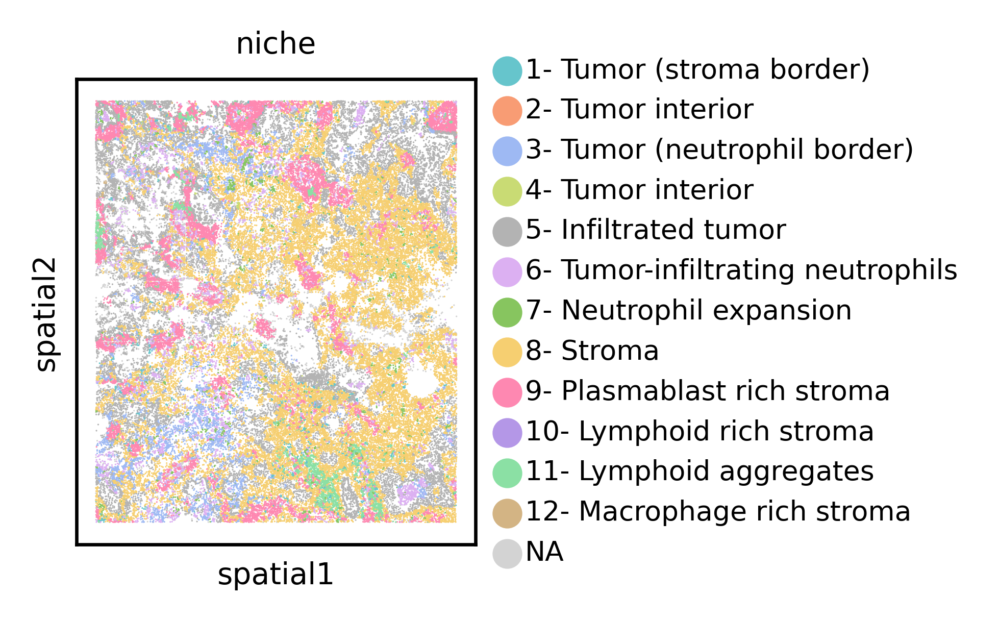

/tmp/ipykernel_4102485/1583793205.py:13: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'batch' as categorical


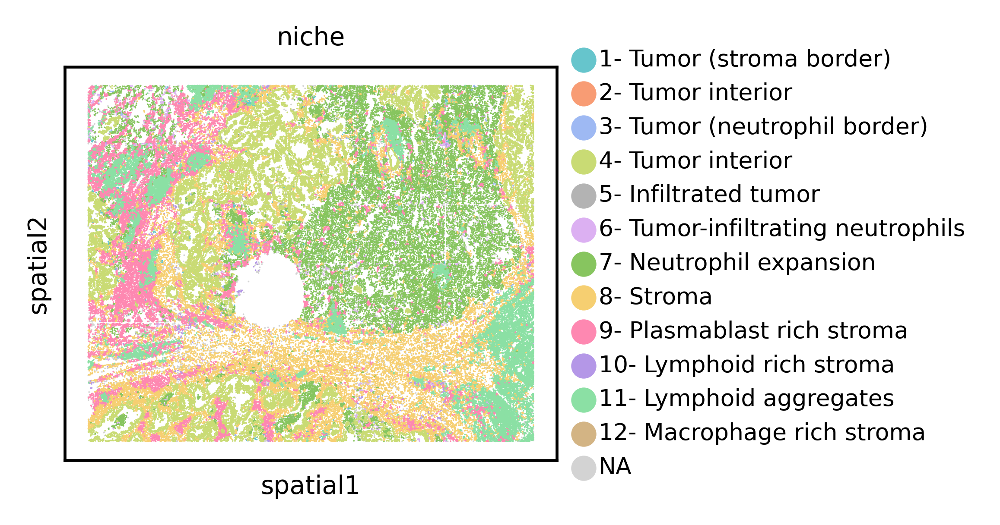

/tmp/ipykernel_4102485/1583793205.py:22: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'batch' as categorical


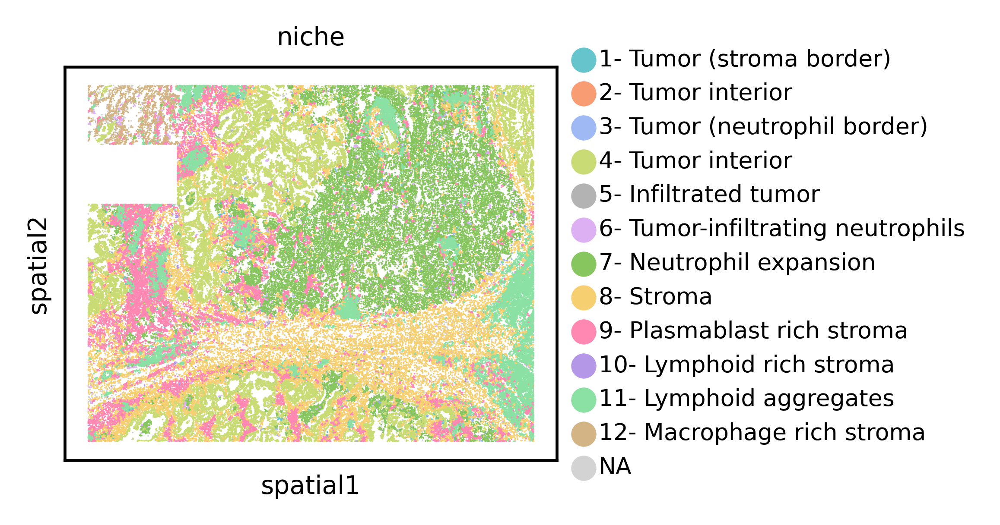

/tmp/ipykernel_4102485/1583793205.py:31: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'batch' as categorical


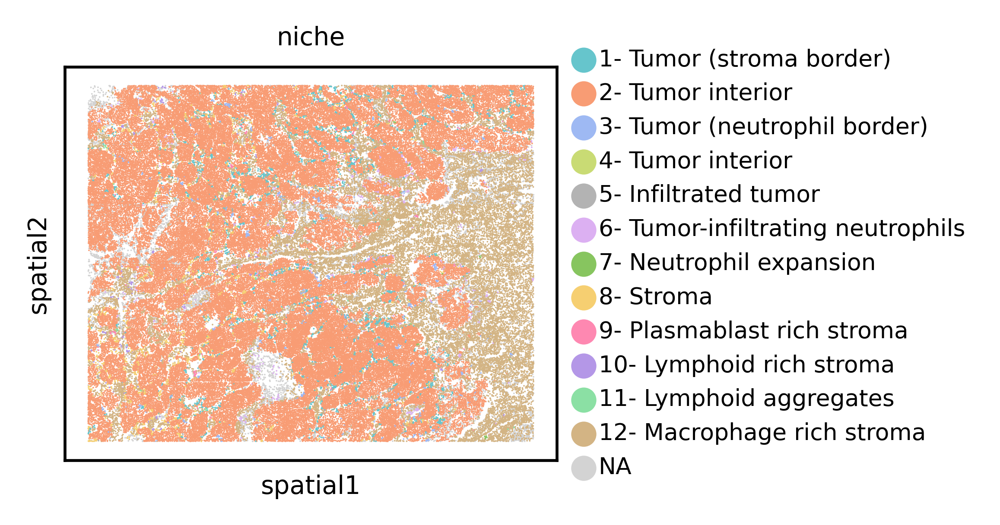

/tmp/ipykernel_4102485/1583793205.py:40: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'batch' as categorical


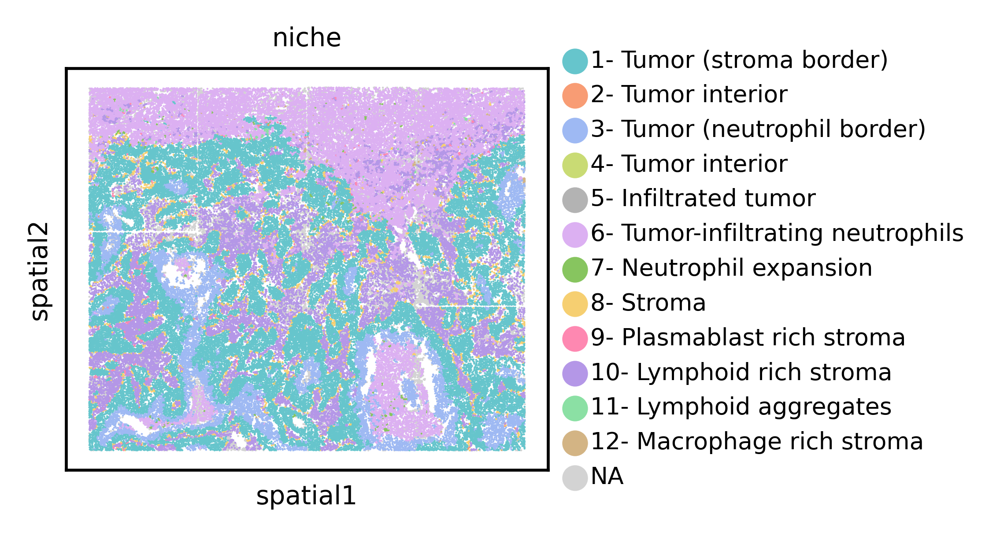

In [48]:
# Visualize ground truth niche labels in training samples
batch = list(set(adata_list[0].obs[sample_key].tolist()))[0]
file_name = f'{dataset_name}_{batch}_niche_label_transfer_ground_truth_niches.svg'
sc.pl.spatial(
    adata_list[0],
    color=niche_key,
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)

batch = list(set(adata_list[1].obs[sample_key].tolist()))[0]
file_name = f'{dataset_name}_{batch}_niche_label_transfer_ground_truth_niches.svg'
sc.pl.spatial(
    adata_list[1],
    color=niche_key,
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)

batch = list(set(adata_list[2].obs[sample_key].tolist()))[0]
file_name = f'{dataset_name}_{batch}_niche_label_transfer_ground_truth_niches.svg'
sc.pl.spatial(
    adata_list[2],
    color=niche_key,
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name) 

batch = list(set(adata_list[3].obs[sample_key].tolist()))[0]
file_name = f'{dataset_name}_{batch}_niche_label_transfer_ground_truth_niches.svg'
sc.pl.spatial(
    adata_list[3],
    color=niche_key,
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name) 

batch = list(set(adata_list[4].obs[sample_key].tolist()))[0]
file_name = f'{dataset_name}_{batch}_niche_label_transfer_ground_truth_niches.svg'
sc.pl.spatial(
    adata_list[4],
    color=niche_key,
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name) 

/tmp/ipykernel_4102485/664958460.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
... storing 'batch' as categorical


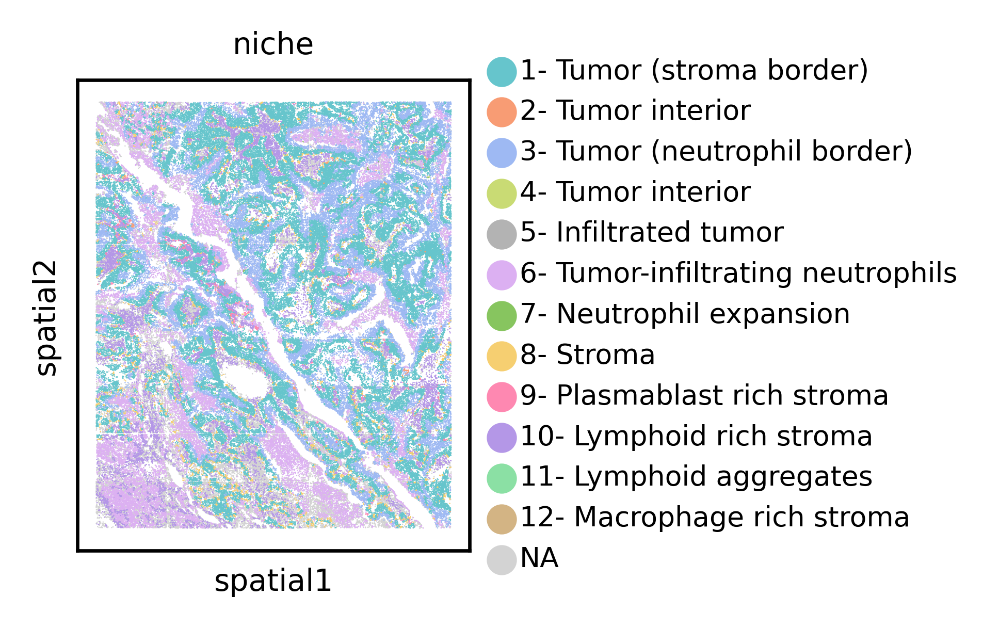

In [49]:
# Visualize ground truth niche labels in test sample
batch = list(set(adata_list[5].obs[sample_key].tolist()))[0]
file_name = f'{dataset_name}_{batch}_niche_label_transfer_ground_truth_niches.svg'
sc.pl.spatial(
    adata_list[5],
    color=niche_key,
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name) 

### 2.2.2 NicheJEPA

In [50]:
method = 'NicheJEPA'
niche_key = 'niche_type'
emb_key = 'neighborhood_emb'

#### 2.2.2.1 Retrieve Embeddings

In [51]:
# Cell and neighborhood embeddings
adata_emb = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded_{model_timestamp}.h5ad')

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [55]:
# Gene embeddings
dataset_list = []

for file_path in file_paths:
    # Load tokenized AnnData or tokenize data
    dataset_path = f'{artifacts_folder_path}/{dataset_name}/{file_path.split("/")[-1].split(".")[0]}.dataset'
    if os.path.exists(dataset_path) and not force_retokenize:
        dataset = load_from_disk(dataset_path)
    else:
        # Tokenize AnnData
        dataset = tokenize_adata(
            adata,
            model_folder_path,
            cache_directory_path,
            nproc=nproc,
            processing_mode='parallel')

        # Save tokenized data
        os.makedirs(f'{artifacts_folder_path}/{dataset_name}', exist_ok=True)
        dataset.save_to_disk(
            dataset_path,
            num_shards=num_shards)

    dataset_list.append(dataset)

full_dataset = concatenate_datasets(dataset_list)

INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614/token_dictionary.pkl.


STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.
Ranking gene tokens based on normalized counts.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:663: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using generator for dataset creation.
Setting num_proc from 4 back to 1 for the train split to disable multiprocessing as it only contains one shard.
Generating train split: 144980 examples [00:24, 6004.59 examples/s] 
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...
Map (num_proc=4): 100%|█| 144980/144980 [01:47<00
Saving the dataset (32/32 shards): 100%|█| 144980
INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614/token_dictionary.pkl.


STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


... (15 outputs left out)

STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:663: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using generator for dataset creation.
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...
Saving the dataset (32/32 shards): 100%|█| 144980


#### 2.2.2.2 Train Niche Transfer Classifiers

In [56]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
print(cat_counts)
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

KeyError: 'niche_type'

##### 2.1.2.2.1 Linear Classifier

In [ ]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm[emb_key]

In [ ]:
adata_list[5].obs[sample_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs[sample_key] != 'batch5').to_numpy().nonzero()[0]
    train_val_labels = niche_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs[sample_key] == 'batch5').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    niche_labels_train = niche_labels[train_indices]
    niche_labels_val = niche_labels[val_indices]
    niche_labels_test = niche_labels[test_indices]

    # Train and evaluate linear niche transfer classifier
    pred_niche_labels_test, _, _, model = linear_classifier(
        features_train=niche_features_train,
        labels_train=niche_labels_train,
        features_val=niche_features_val,
        labels_val=niche_labels_val,
        features_test=niche_features_test,
        labels_test=niche_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )
    
    #print(niche_categories[pred_niche_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_{model_timestamp}_niche_label_transfer_linear_classifer_predicted_niches_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.2.2.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'batch5').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'batch5').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [ ]:
# Train and evaluate knn niche transfer classifier
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_niche_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_{model_timestamp}_niche_label_transfer_knn_classifer_predicted_niches.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.2.2.3 Train Cell Type Transfer Classifiers

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

##### 2.1.2.3.1 Linear Classifier

In [ ]:
# Retrieve features and labels
cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm['cell_emb']

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs['sample'] != 'batch5').to_numpy().nonzero()[0]
    train_val_labels = cell_type_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs['sample'] == 'batch5').to_numpy().nonzero()[0]
    
    # Split features and labels
    cell_type_features_train = cell_type_features[train_indices]
    cell_type_features_val = cell_type_features[val_indices]
    cell_type_features_test = cell_type_features[test_indices]
    cell_type_labels_train = cell_type_labels[train_indices]
    cell_type_labels_val = cell_type_labels[val_indices]
    cell_type_labels_test = cell_type_labels[test_indices]

    # Train and evaluate linear cell type transfer classifier
    pred_cell_type_labels_test, _, _, model = linear_classifier(
        features_train=cell_type_features_train,
        labels_train=cell_type_labels_train,
        features_val=cell_type_features_val,
        labels_val=cell_type_labels_val,
        features_test=cell_type_features_test,
        labels_test=cell_type_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )

    #print(cell_type_categories[pred_cell_type_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{cell_type_key}_pred_linear'] = cell_type_categories[pred_cell_type_labels_test]

In [ ]:
# Visualize predicted cell type labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_{model_timestamp}_cell_type_label_transfer_linear_classifer_predicted_cell_types_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_linear',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.2.3.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'batch5').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'batch5').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [ ]:
# Train and evaluate knn cell type transfer classifier
pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_cell_type_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_{model_timestamp}_cell_type_label_transfer_knn_classifer_predicted_cell_types.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.2.2.4 Train Neighborhood Composition Classifiers

In [ ]:
# Compute spatial neighborhood graph
adata_batch_list = []
batches = adata_emb.obs[batch_key].unique().tolist()

for batch in batches:
    adata_batch = adata_emb[adata_emb.obs[batch_key] == batch]
    print('Computing spatial neighborhood...')
    # Construct neighbor graph
    adata_batch = construct_neighbor_graph(
        adata_batch,
        n_neighs=n_neighs,
        radius=None,
        delaunay=None,
        include_self_loop=False,
        compute_neighbor_counts=False)
    adata_batch_list.append(adata_batch)

adata_combined = sc.concat(adata_batch_list, join="inner")

# Combine spatial neighborhood graphs as disconnected components
batch_connectivities = []
len_before_batch = 0
for i in range(len(adata_batch_list)):
    if i == 0: # first batch
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[0].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[0].shape[0])))
        batch_connectivities.append(sp.hstack(
            (adata_batch_list[0].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    elif i == (len(adata_batch_list) - 1): # last batch
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0])))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'])))
    else: # middle batches
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0], len_before_batch))
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0] -
            len_before_batch)))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    len_before_batch += adata_batch_list[i].shape[0]
connectivities = sp.vstack(batch_connectivities)
adata_combined.obsp['spatial_connectivities'] = connectivities

composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
cell_type_composition_labels = composition_df.values
niche_features = adata_emb.obsm['neighborhood_emb']

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get neighborhood composition labels and features
    composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
    cell_type_composition_labels = composition_df.values
    niche_features = adata_emb.obsm['neighborhood_emb']
    
    # Get train and validation indices
    train_val_indices = (adata_emb.obs[sample_key] != 'batch5').to_numpy().nonzero()[0]
    train_val_labels = cell_type_composition_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        #stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_emb.obs[sample_key] == 'batch5').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
    cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
    cell_type_composition_labels_test = cell_type_composition_labels[test_indices]
    
    pred_cell_type_composition_labels, model = linear_regressor(
        features_train=niche_features_train,
        labels_train=cell_type_composition_labels_train,
        features_val=niche_features_val,
        labels_val=cell_type_composition_labels_val,
        features_test=niche_features_test,
        labels_test=cell_type_composition_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_neighborhood_composition_linear_classifier_cls_report_seed_{seed}.txt'
    )
    
    print(pred_cell_type_composition_labels)

#### 2.2.2.5 Ligand-Receptor Prediction

##### 2.1.2.5.1 CellPhoneDB

In [ ]:
lr_database = 'cellphonedb'

In [ ]:
# Get Ensembl IDs
adata_emb.var = adata_list[0].var

In [ ]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata_emb,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata_emb,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')
print(lr_interaction_df)

# Randomly shuffle rows
lr_interaction_df = lr_interaction_df.sample(
    frac=1, random_state=0).reset_index(drop=True)

In [ ]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_average_gene_embed_{lr_database}.pkl'

if os.path.exists(file_path):
    with open(file_path, "rb") as f:
        output_average_gene_embed = pickle.load(f)
else:
    cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
    neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()
    
    output_average_gene_embed = get_average_gene_embed(
        dataset=full_dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers,
        cell_gene_ensembl_id=cell_gene_ensembl_id,
        neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
    )
    
    with open(file_path, "wb") as f:
        pickle.dump(output_average_gene_embed, f)

In [ ]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

### Use second half of ligand-receptor pairs as negative pairs ###
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    train_ratio = 0.8
    test_ratio = 0.1
    val_ratio = 0.1
    
    # --- Splitting using sklearn ---
    # First, split off the test set
    ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
        ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)
    
    # Then split the remaining temp set into train and val
    # The new val ratio is relative to the remaining data
    val_relative_ratio = val_ratio / (train_ratio + val_ratio)
    
    ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
        ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)
    
    # Train and evaluate linear ligand-receptor classifier
    pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
        features_train=ligand_receptor_features_train,
        labels_train=ligand_receptor_labels_train,
        features_val=ligand_receptor_features_val,
        labels_val=ligand_receptor_labels_val,
        features_test=ligand_receptor_features_test,
        labels_test=ligand_receptor_labels_test,
        n_epochs=500,
        batch_size=16,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_cls_report_seed_{seed}.txt'
        )

    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_pred_lr_labels_seed_{seed}.txt', "wb") as f:
        pickle.dump(pred_lr_labels, f)
    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_lr_labels_seed_{seed}.txt', "wb") as f:
        pickle.dump(lr_labels, f)
    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_lr_logits_seed_{seed}.txt', "wb") as f:
        pickle.dump(lr_logits, f)

##### 2.1.2.5.2 OmniPath

In [ ]:
lr_database = 'omnipath'

In [ ]:
# Get Ensembl IDs
adata_emb.var = adata_list[0].var

In [ ]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata_emb,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata_emb,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')
print(lr_interaction_df)

# Randomly shuffle rows
lr_interaction_df = lr_interaction_df.sample(
    frac=1, random_state=0).reset_index(drop=True)

In [ ]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_average_gene_embed_{lr_database}.pkl'

if os.path.exists(file_path):
    with open(file_path, "rb") as f:
        output_average_gene_embed = pickle.load(f)
else:
    cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
    neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()
    
    output_average_gene_embed = get_average_gene_embed(
        dataset=full_dataset,
        model_folder_path=model_folder_path,
        emb_layer=emb_layer,
        batch_size=batch_size,
        pin_memory=pin_memory,
        num_workers=num_workers,
        cell_gene_ensembl_id=cell_gene_ensembl_id,
        neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
    )
    
    with open(file_path, "wb") as f:
        pickle.dump(output_average_gene_embed, f)

In [ ]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

### Use second half of ligand-receptor pairs as negative pairs ###
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    train_ratio = 0.8
    test_ratio = 0.1
    val_ratio = 0.1
    
    # --- Splitting using sklearn ---
    # First, split off the test set
    ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
        ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)
    
    # Then split the remaining temp set into train and val
    # The new val ratio is relative to the remaining data
    val_relative_ratio = val_ratio / (train_ratio + val_ratio)
    
    ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
        ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)
    
    # Train and evaluate linear ligand-receptor classifier
    pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
        features_train=ligand_receptor_features_train,
        labels_train=ligand_receptor_labels_train,
        features_val=ligand_receptor_features_val,
        labels_val=ligand_receptor_labels_val,
        features_test=ligand_receptor_features_test,
        labels_test=ligand_receptor_labels_test,
        n_epochs=500,
        batch_size=16,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_cls_report_seed_{seed}.txt'
        )

    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_pred_lr_labels_seed_{seed}.txt', "wb") as f:
        pickle.dump(pred_lr_labels, f)
    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_lr_labels_seed_{seed}.txt', "wb") as f:
        pickle.dump(lr_labels, f)
    with open(f'{benchmarking_artifacts_folder_path}/results/{method}_{model_timestamp}_{dataset_name}_ligand_receptor_prediction_linear_classifier_lr_logits_seed_{seed}.txt', "wb") as f:
        pickle.dump(lr_logits, f)

In [ ]:
# Harmonize and tokenize data and retrieve embeddings
force_retokenize = False
force_recompute_output_embed = False

adata_list = []
dataset_list = []
output_embed_list = []

for file_path in file_paths:
    # Load AnnData
    adata = sc.read_h5ad(file_path)

    # Harmonize AnnData
    adata = harmonize_adata(adata)
    adata_list.append(adata)

    # Load tokenized AnnData or tokenize data
    dataset_path = f'{artifacts_folder_path}/{dataset_name}/{file_path.split("/")[-1].split(".")[0]}.dataset'
    if os.path.exists(dataset_path) and not force_retokenize:
        dataset = load_from_disk(dataset_path)
        print('Filtering cells...')
        # Filter cells based on adata.obs['filter_pass']
        adata = filter_cells(adata)   
        
        print('Computing spatial neighborhood...')
        # Construct neighbor graph
        adata = construct_neighbor_graph(
            adata,
            n_neighs=n_neighs,
            radius=None,
            delaunay=None,
            include_self_loop=False,
            compute_neighbor_counts=False)
    else:
        # Tokenize AnnData
        dataset = tokenize_adata(
            adata,
            model_folder_path,
            nproc=nproc,
            processing_mode='parallel')

        # Save tokenized data
        os.makedirs(f'{artifacts_folder_path}/{dataset_name}', exist_ok=True)
        dataset.save_to_disk(
            dataset_path,
            num_shards=num_shards)
    dataset_list.append(dataset)

    # Retrieve cell and neighborhood embeddings
    output_embed_path = f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}/{file_path.split("/")[-1].split(".")[0]}_output_embed.pkl'
    if os.path.exists(output_embed_path) and not force_recompute_output_embed:
        with open(output_embed_path, 'rb') as f:
            output_embed = pickle.load(f)
    else:
        # Compute embeddings
        output_embed = embed_dataset(
            dataset=dataset,
            model_folder_path=model_folder_path,
            emb_layer=emb_layer,
            agg_excluded_tokens=agg_excluded_tokens,
            top_k=top_k,
            batch_size=batch_size,
            pin_memory=pin_memory,
            num_workers=num_workers)

        # Save embeddings
        os.makedirs(f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}', exist_ok=True)
        with open(output_embed_path, 'wb') as f:
            pickle.dump(output_embed, f)
    output_embed_list.append(output_embed)

### 2.2.3 CellPLM

### 2.2.4 Nicheformer

### 2.2.5 Novae

### 2.2.6 scGPT-spatial

In [ ]:
method = 'scGPT-spatial'
niche_key = 'niche'
emb_key = 'X'

#### 2.1.6.1 Retrieve Embeddings

In [ ]:
adata_emb = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
print(cat_counts)
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

#### 2.1.6.2 Train Niche Transfer Classifiers

##### 2.1.6.2.1 Linear Classifier

In [ ]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs[sample_key] != 'batch5').to_numpy().nonzero()[0]
    train_val_labels = niche_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs[sample_key] == 'batch5').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    niche_labels_train = niche_labels[train_indices]
    niche_labels_val = niche_labels[val_indices]
    niche_labels_test = niche_labels[test_indices]

    # Train and evaluate linear niche transfer classifier
    pred_niche_labels_test, _, _, model = linear_classifier(
        features_train=niche_features_train,
        labels_train=niche_labels_train,
        features_val=niche_features_val,
        labels_val=niche_labels_val,
        features_test=niche_features_test,
        labels_test=niche_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )
    
    #print(niche_categories[pred_niche_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

In [ ]:
# Visualize predicted niche labels in test sample
file_name = f'{method}_{dataset_name}_batch19_niche_label_transfer_linear_classifer_predicted_niches_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.6.2.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [ ]:
# Train and evaluate linear niche transfer classifier
# 0.828 accuracy
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
file_name = f'{method}_{dataset_name}_batch19_niche_label_transfer_linear_classifer_predicted_niches_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

In [ ]:
for i in range(len(adata_list)):
    adata_list[i].obs['batch'] = adata_list[i].uns['batch']

# Concatenate AnnData objects of all samples/batches
adata = sc.concat(adata_list, axis=0)

# Retrieve cell and neighborhood embeddings for all samples/batches
cell_emb = np.concatenate([output_embed['cell_emb'] for output_embed in output_embed_list], axis=0)
spatial_cell_emb = np.concatenate([output_embed['spatial_cell_emb'] for output_embed in output_embed_list], axis=0)
neighborhood_emb = np.concatenate([output_embed['neighborhood_emb'] for output_embed in output_embed_list], axis=0)

# Add embeddings to AnnData object
adata.obsm['cell_emb'] = cell_emb
adata.obsm['spatial_cell_emb'] = spatial_cell_emb
adata.obsm['neighborhood_emb'] = neighborhood_emb

# Add combined neighborhood graph
blocks = [a.obsp['spatial_connectivities'] for a in adata_list]
combined_graph = sp.block_diag(blocks)
adata.obsp['spatial_connectivities'] = combined_graph.tocsr()

# Write to disk
adata.write(f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}/{file_path.split("/")[-1].split(".")[0]}.h5ad')

#### 2.2.2 Train Niche Transfer Classifier

In [ ]:
# Get unique niche labels
set(adata_list[0].obs[niche_key].unique().tolist() +
    adata_list[1].obs[niche_key].unique().tolist() +
    adata_list[2].obs[niche_key].unique().tolist() +
    adata_list[3].obs[niche_key].unique().tolist() +
    adata_list[4].obs[niche_key].unique().tolist() +
    adata_list[5].obs[niche_key].unique().tolist())

In [ ]:
adata_test = adata_list[-1]

In [ ]:
# Visualize ground truth niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=niche_key,
    palette=custom_palette,
    spot_size=spot_size)   

In [ ]:
# Filter cells with missing labels
adata_filtered = adata[~adata.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

##### 2.2.1.1 Linear Classifier

In [ ]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm['neighborhood_emb']

In [ ]:
# Get train and validation indices
train_val_indices = (adata_filtered.obs['batch'] != 'batch5').to_numpy().nonzero()[0]
train_val_labels = niche_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    stratify=train_val_labels
)

# Get test indices
test_indices = (adata_filtered.obs['batch'] == 'batch5').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_val = niche_features[val_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_val = niche_labels[val_indices]
niche_labels_test = niche_labels[test_indices]

In [ ]:
# Train and evaluate linear niche transfer classifier
# 0.832 accuracy
pred_niche_labels_test, _, _, model = linear_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_val=niche_features_val,
    labels_val=niche_labels_val,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(niche_categories[pred_niche_labels_test])

In [ ]:
adata_test = adata_filtered[adata_filtered.obs['batch'] == 'batch5']

In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

In [ ]:
# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=custom_palette,
    spot_size=spot_size)   

##### 2.2.1.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs['batch'] != 'batch5').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs['batch'] == 'batch5').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [ ]:
# Train and evaluate linear niche transfer classifier
# 0.789 accuracy
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test)

In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=custom_palette,
    spot_size=spot_size)   

#### 2.2.3 Ligand-Receptor Prediction

In [ ]:
lr_database = 'cellphonedb'

In [ ]:
adata.var = adata_list[0].var

In [ ]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')

print(lr_interaction_df)

In [ ]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()

output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [ ]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

# Use second half og ligand-receptor pairs as negative pairs
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])


In [ ]:
seed = 0
train_ratio = 0.8
test_ratio = 0.1
val_ratio = 0.1

In [ ]:
# --- Splitting using sklearn ---
# First, split off the test set
ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
    ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)

# Then split the remaining temp set into train and val
# The new val ratio is relative to the remaining data
val_relative_ratio = val_ratio / (train_ratio + val_ratio)

ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
    ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)

In [ ]:
pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
    features_train=ligand_receptor_features_train,
    labels_train=ligand_receptor_labels_train,
    features_val=ligand_receptor_features_val,
    labels_val=ligand_receptor_labels_val,
    features_test=ligand_receptor_features_test,
    labels_test=ligand_receptor_labels_test,
    n_epochs=400,
    batch_size=16,
    )

In [ ]:
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from scipy.special import softmax

# Convert to numpy arrays
logits = np.stack(lr_logits)             # shape (N, 2)
labels = np.array(lr_labels)             # shape (N,)

# Apply softmax to get probabilities
probs = softmax(logits, axis=1)       # shape (N, 2)
pos_probs = probs[:, 1]               # probability of class 1

# Compute ROC curve and AUC
fpr, tpr, _ = roc_curve(labels, pos_probs)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure()
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

### 2.2.7 scGPT

## 2.3 xhk1007-41b_1p (Xenium Human Kidney RCC)

In [ ]:
# Dataset variables
dataset_name = 'xhk1007-CV1-41b_1p'
cell_type_key = 'level_1_cell_type'
sample_key = 'batch'
test_sample = 'batch14'
file_paths = [
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/CV1-KID-0-FT-3.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/CV1-KID-0-FT-1.h5ad']
spot_size = 30

In [ ]:
# Model variables
seed = 0
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None

train_ratio = 0.8
test_ratio = 0.1
val_ratio = 0.1

In [ ]:
# Tokenizer variables
num_shards = 32
nproc = 4
n_neighs = 10

#### 2.3.1 Retrieve Embeddings

In [ ]:
# Harmonize and tokenize data and retrieve embeddings
force_retokenize = False
force_recompute_output_embed = False

adata_list = []
dataset_list = []
output_embed_list = []

for file_path in file_paths:
    # Load AnnData
    adata = sc.read_h5ad(file_path)

    # Harmonize AnnData
    adata = harmonize_adata(adata)
    adata_list.append(adata)

    # Load tokenized AnnData or tokenize data
    dataset_path = f'{artifacts_folder_path}/{dataset_name}/{file_path.split("/")[-1].split(".")[0]}.dataset'
    if os.path.exists(dataset_path) and not force_retokenize:
        dataset = load_from_disk(dataset_path)
        print('Filtering cells...')
        # Filter cells based on adata.obs['filter_pass']
        adata = filter_cells(adata)   
        
        print('Computing spatial neighborhood...')
        # Construct neighbor graph
        adata = construct_neighbor_graph(
            adata,
            n_neighs=n_neighs,
            radius=None,
            delaunay=None,
            include_self_loop=False,
            compute_neighbor_counts=False)
    else:
        # Tokenize AnnData
        dataset = tokenize_adata(
            adata,
            model_folder_path,
            nproc=nproc,
            processing_mode='parallel')

        # Save tokenized data
        os.makedirs(f'{artifacts_folder_path}/{dataset_name}', exist_ok=True)
        dataset.save_to_disk(
            dataset_path,
            num_shards=num_shards)
    dataset_list.append(dataset)

    # Retrieve cell and neighborhood embeddings
    output_embed_path = f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}/{file_path.split("/")[-1].split(".")[0]}_output_embed.pkl'
    if os.path.exists(output_embed_path) and not force_recompute_output_embed:
        with open(output_embed_path, 'rb') as f:
            output_embed = pickle.load(f)
    else:
        # Compute embeddings
        output_embed = embed_dataset(
            dataset=dataset,
            model_folder_path=model_folder_path,
            emb_layer=emb_layer,
            agg_excluded_tokens=agg_excluded_tokens,
            top_k=top_k,
            batch_size=batch_size,
            pin_memory=pin_memory,
            num_workers=num_workers)

        # Save embeddings
        os.makedirs(f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}', exist_ok=True)
        with open(output_embed_path, 'wb') as f:
            pickle.dump(output_embed, f)
    output_embed_list.append(output_embed)

In [ ]:
for i in range(len(adata_list)):
    adata_list[i].obs['batch'] = adata_list[i].uns['batch']

# Concatenate AnnData objects of all samples/batches
adata = sc.concat(adata_list, axis=0)

# Retrieve cell and neighborhood embeddings for all samples/batches
cell_emb = np.concatenate([output_embed['cell_emb'] for output_embed in output_embed_list], axis=0)
spatial_cell_emb = np.concatenate([output_embed['spatial_cell_emb'] for output_embed in output_embed_list], axis=0)
neighborhood_emb = np.concatenate([output_embed['neighborhood_emb'] for output_embed in output_embed_list], axis=0)

# Add embeddings to AnnData object
adata.obsm['cell_emb'] = cell_emb
adata.obsm['spatial_cell_emb'] = spatial_cell_emb
adata.obsm['neighborhood_emb'] = neighborhood_emb

# Add combined neighborhood graph
blocks = [a.obsp['spatial_connectivities'] for a in adata_list]
combined_graph = sp.block_diag(blocks)
adata.obsp['spatial_connectivities'] = combined_graph.tocsr()

# Write to disk
adata.write(f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}/{file_path.split("/")[-1].split(".")[0]}.h5ad')

#### 2.3.2 Train Cell Type Transfer Classifier

In [ ]:
# Get unique niche labels
set(adata_list[0].obs[cell_type_key].unique().tolist() +
    adata_list[1].obs[cell_type_key].unique().tolist())

In [ ]:
custom_palette = {
    'Endothelium': '#1f78b4',
    'Epithelium': '#33a02c',
    'Lymphoid': '#fb9a99',
    'Myeloid': '#e31a1c',
    'Stroma': '#a6cee3'
}

In [ ]:
# Visualize ground truth cell type labels in training samples
sc.pl.spatial(
    adata_list[0],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=spot_size)   

In [ ]:
# Visualize ground truth cell type labels in test sample
sc.pl.spatial(
    adata_list[1],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=spot_size)   

In [ ]:
# Filter cells with missing labels
adata_filtered = adata[~adata.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm['cell_emb']

# Get train and validation indices
train_val_indices = (adata_filtered.obs[sample_key] != test_sample).to_numpy().nonzero()[0]
train_val_labels = cell_type_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    stratify=train_val_labels
)

# Get test indices
test_indices = (adata_filtered.obs[sample_key] == test_sample).to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_val = cell_type_features[val_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_val = cell_type_labels[val_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [ ]:
# Train and evaluate linear niche transfer classifier
# 0.891 accuracy
pred_cell_type_labels_test, _, _, model = linear_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_val=cell_type_features_val,
    labels_val=cell_type_labels_val,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(cell_type_categories[pred_cell_type_labels_test])

In [ ]:
adata_test = adata_list[1]

In [ ]:
adata_test.obs[f'{cell_type_key}_pred_linear'] = cell_type_categories[pred_cell_type_labels_test]

In [ ]:
# Visualize predicted labels
sc.pl.spatial(
    adata_list[1],
    color=f'{cell_type_key}_pred_linear',
    palette=custom_palette,
    spot_size=spot_size)   

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != test_sample).to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == test_sample).to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test)

adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=custom_palette,
    spot_size=30)   

#### 2.3.3 Train Neighborhood Composition Transfer Classifier

In [ ]:
# Get neighborhood composition labels and features
composition_df = compute_neighborhood_composition(adata, cell_type_key)
cell_type_composition_labels = composition_df.values
niche_features = adata.obsm['neighborhood_emb']

# Get train and validation indices
train_val_indices = (adata.obs[sample_key] != test_sample).to_numpy().nonzero()[0]
train_val_labels = cell_type_composition_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    #stratify=train_val_labels
)

# Get test indices
test_indices = (adata.obs[sample_key] == test_sample).to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_val = niche_features[val_indices]
niche_features_test = niche_features[test_indices]
cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
cell_type_composition_labels_test = cell_type_composition_labels[test_indices]

pred_cell_type_composition_labels, model = linear_regressor(
    features_train=niche_features_train,
    labels_train=cell_type_composition_labels_train,
    features_val=niche_features_val,
    labels_val=cell_type_composition_labels_val,
    features_test=niche_features_test,
    labels_test=cell_type_composition_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(pred_cell_type_composition_labels)

#### 2.3.4 Ligand-Receptor Prediction

In [ ]:
lr_database = 'cellphonedb'

In [ ]:
adata.var = adata_list[0].var

In [ ]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')

In [ ]:
lr_interaction_df

In [ ]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()

output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [ ]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

# Use second half og ligand-receptor pairs as negative pairs
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])


In [ ]:
# --- Splitting using sklearn ---
# First, split off the test set
ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
    ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)

# Then split the remaining temp set into train and val
# The new val ratio is relative to the remaining data
val_relative_ratio = val_ratio / (train_ratio + val_ratio)

ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
    ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)

In [ ]:
pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
    features_train=ligand_receptor_features_train,
    labels_train=ligand_receptor_labels_train,
    features_val=ligand_receptor_features_val,
    labels_val=ligand_receptor_labels_val,
    features_test=ligand_receptor_features_test,
    labels_test=ligand_receptor_labels_test,
    n_epochs=400,
    batch_size=16,
    )

In [ ]:
plot_roc_curve(logits=lr_logits, labels=lr_labels)

#### 2.1.6.1 Retrieve Embeddings

In [ ]:
# Cell embeddings
adata_emb = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

#### 2.1.6.2 Train Niche Transfer Classifiers

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
print(cat_counts)
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

##### 2.1.6.2.1 Linear Classifier

In [ ]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = niche_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    niche_labels_train = niche_labels[train_indices]
    niche_labels_val = niche_labels[val_indices]
    niche_labels_test = niche_labels[test_indices]

    # Train and evaluate linear niche transfer classifier
    pred_niche_labels_test, _, _, model = linear_classifier(
        features_train=niche_features_train,
        labels_train=niche_labels_train,
        features_val=niche_features_val,
        labels_val=niche_labels_val,
        features_test=niche_features_test,
        labels_test=niche_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )
    
    #print(niche_categories[pred_niche_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_niche_label_transfer_linear_classifer_predicted_niches_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.6.2.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [ ]:
# Train and evaluate knn niche transfer classifier
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_niche_label_transfer_knn_classifer_predicted_niches.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.6.3 Train Cell Type Transfer Classifiers

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

##### 2.1.6.3.1 Linear Classifier

In [ ]:
# Retrieve features and labels
cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    cell_type_features_train = cell_type_features[train_indices]
    cell_type_features_val = cell_type_features[val_indices]
    cell_type_features_test = cell_type_features[test_indices]
    cell_type_labels_train = cell_type_labels[train_indices]
    cell_type_labels_val = cell_type_labels[val_indices]
    cell_type_labels_test = cell_type_labels[test_indices]

    # Train and evaluate linear cell type transfer classifier
    pred_cell_type_labels_test, _, _, model = linear_classifier(
        features_train=cell_type_features_train,
        labels_train=cell_type_labels_train,
        features_val=cell_type_features_val,
        labels_val=cell_type_labels_val,
        features_test=cell_type_features_test,
        labels_test=cell_type_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )

    #print(cell_type_categories[pred_cell_type_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{cell_type_key}_pred_linear'] = cell_type_categories[pred_cell_type_labels_test]

In [ ]:
# Visualize predicted cell type labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_cell_type_label_transfer_linear_classifer_predicted_cell_types_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_linear',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.6.3.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [ ]:
# Train and evaluate knn cell type transfer classifier
pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_cell_type_label_transfer_knn_classifer_predicted_cell_types.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.6.4 Train Neighborhood Composition Classifiers

In [ ]:
# Compute spatial neighborhood graph
adata_batch_list = []
batches = adata_emb.obs[batch_key].unique().tolist()

for batch in batches:
    adata_batch = adata_emb[adata_emb.obs[batch_key] == batch]
    print('Computing spatial neighborhood...')
    # Construct neighbor graph
    adata_batch = construct_neighbor_graph(
        adata_batch,
        n_neighs=n_neighs,
        radius=None,
        delaunay=None,
        include_self_loop=False,
        compute_neighbor_counts=False)
    adata_batch_list.append(adata_batch)

adata_combined = sc.concat(adata_batch_list, join="inner")

# Combine spatial neighborhood graphs as disconnected components
batch_connectivities = []
len_before_batch = 0
for i in range(len(adata_batch_list)):
    if i == 0: # first batch
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[0].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[0].shape[0])))
        batch_connectivities.append(sp.hstack(
            (adata_batch_list[0].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    elif i == (len(adata_batch_list) - 1): # last batch
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0])))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'])))
    else: # middle batches
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0], len_before_batch))
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0] -
            len_before_batch)))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    len_before_batch += adata_batch_list[i].shape[0]
connectivities = sp.vstack(batch_connectivities)
adata_combined.obsp['spatial_connectivities'] = connectivities

composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
cell_type_composition_labels = composition_df.values
niche_features = adata_emb.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get neighborhood composition labels and features
    composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
    cell_type_composition_labels = composition_df.values
    niche_features = adata_emb.obsm[emb_key]
    
    # Get train and validation indices
    train_val_indices = (adata_emb.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_composition_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        #stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_emb.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
    cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
    cell_type_composition_labels_test = cell_type_composition_labels[test_indices]
    
    pred_cell_type_composition_labels, model = linear_regressor(
        features_train=niche_features_train,
        labels_train=cell_type_composition_labels_train,
        features_val=niche_features_val,
        labels_val=cell_type_composition_labels_val,
        features_test=niche_features_test,
        labels_test=cell_type_composition_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_neighborhood_composition_linear_classifier_cls_report_seed_{seed}.txt'
    )
    
    print(pred_cell_type_composition_labels)

#### 2.1.6.1 Retrieve Embeddings

In [ ]:
# Cell embeddings
adata_emb = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

#### 2.1.6.2 Train Niche Transfer Classifiers

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
print(cat_counts)
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

##### 2.1.6.2.1 Linear Classifier

In [ ]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = niche_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    niche_labels_train = niche_labels[train_indices]
    niche_labels_val = niche_labels[val_indices]
    niche_labels_test = niche_labels[test_indices]

    # Train and evaluate linear niche transfer classifier
    pred_niche_labels_test, _, _, model = linear_classifier(
        features_train=niche_features_train,
        labels_train=niche_labels_train,
        features_val=niche_features_val,
        labels_val=niche_labels_val,
        features_test=niche_features_test,
        labels_test=niche_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )
    
    #print(niche_categories[pred_niche_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_niche_label_transfer_linear_classifer_predicted_niches_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.6.2.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [ ]:
# Train and evaluate knn niche transfer classifier
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_niche_label_transfer_knn_classifer_predicted_niches.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.6.3 Train Cell Type Transfer Classifiers

In [ ]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

##### 2.1.6.3.1 Linear Classifier

In [ ]:
# Retrieve features and labels
cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    cell_type_features_train = cell_type_features[train_indices]
    cell_type_features_val = cell_type_features[val_indices]
    cell_type_features_test = cell_type_features[test_indices]
    cell_type_labels_train = cell_type_labels[train_indices]
    cell_type_labels_val = cell_type_labels[val_indices]
    cell_type_labels_test = cell_type_labels[test_indices]

    # Train and evaluate linear cell type transfer classifier
    pred_cell_type_labels_test, _, _, model = linear_classifier(
        features_train=cell_type_features_train,
        labels_train=cell_type_labels_train,
        features_val=cell_type_features_val,
        labels_val=cell_type_labels_val,
        features_test=cell_type_features_test,
        labels_test=cell_type_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )

    #print(cell_type_categories[pred_cell_type_labels_test])

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{cell_type_key}_pred_linear'] = cell_type_categories[pred_cell_type_labels_test]

In [ ]:
# Visualize predicted cell type labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_cell_type_label_transfer_linear_classifer_predicted_cell_types_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_linear',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.6.3.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [ ]:
# Train and evaluate knn cell type transfer classifier
pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sample = list(set(adata_test.obs[sample_key].tolist()))[0]
batch = list(set(adata_test.obs[batch_key].tolist()))[0]
print(sample)
file_name = f'{dataset_name}_{batch}_{method}_cell_type_label_transfer_knn_classifer_predicted_cell_types.svg'
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=cell_type_palette,
    spot_size=spot_size,
    save=file_name)   

#### 2.1.6.4 Train Neighborhood Composition Classifiers

In [ ]:
# Compute spatial neighborhood graph
adata_batch_list = []
batches = adata_emb.obs[batch_key].unique().tolist()

for batch in batches:
    adata_batch = adata_emb[adata_emb.obs[batch_key] == batch]
    print('Computing spatial neighborhood...')
    # Construct neighbor graph
    adata_batch = construct_neighbor_graph(
        adata_batch,
        n_neighs=n_neighs,
        radius=None,
        delaunay=None,
        include_self_loop=False,
        compute_neighbor_counts=False)
    adata_batch_list.append(adata_batch)

adata_combined = sc.concat(adata_batch_list, join="inner")

# Combine spatial neighborhood graphs as disconnected components
batch_connectivities = []
len_before_batch = 0
for i in range(len(adata_batch_list)):
    if i == 0: # first batch
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[0].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[0].shape[0])))
        batch_connectivities.append(sp.hstack(
            (adata_batch_list[0].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    elif i == (len(adata_batch_list) - 1): # last batch
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0])))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'])))
    else: # middle batches
        before_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0], len_before_batch))
        after_batch_connectivities_extension = sp.csr_matrix(
            (adata_batch_list[i].shape[0],
            (adata_combined.shape[0] -
            adata_batch_list[i].shape[0] -
            len_before_batch)))
        batch_connectivities.append(sp.hstack(
            (before_batch_connectivities_extension,
            adata_batch_list[i].obsp['spatial_connectivities'],
            after_batch_connectivities_extension)))
    len_before_batch += adata_batch_list[i].shape[0]
connectivities = sp.vstack(batch_connectivities)
adata_combined.obsp['spatial_connectivities'] = connectivities

composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
cell_type_composition_labels = composition_df.values
niche_features = adata_emb.obsm[emb_key]

In [ ]:
n_seeds = 8

for seed in range(n_seeds):
    # Get neighborhood composition labels and features
    composition_df = compute_neighborhood_composition(adata_combined, cell_type_key)
    cell_type_composition_labels = composition_df.values
    niche_features = adata_emb.obsm[emb_key]
    
    # Get train and validation indices
    train_val_indices = (adata_emb.obs[sample_key] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = cell_type_composition_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        #stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_emb.obs[sample_key] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
    cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
    cell_type_composition_labels_test = cell_type_composition_labels[test_indices]
    
    pred_cell_type_composition_labels, model = linear_regressor(
        features_train=niche_features_train,
        labels_train=cell_type_composition_labels_train,
        features_val=niche_features_val,
        labels_val=cell_type_composition_labels_val,
        features_test=niche_features_test,
        labels_test=cell_type_composition_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_neighborhood_composition_linear_classifier_cls_report_seed_{seed}.txt'
    )
    
    print(pred_cell_type_composition_labels)

In [ ]:
# Retrieve F1 scores
weighted_avg_f1_scores = []
for seed in range(n_seeds):
    with open(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_niche_label_transfer_cls_report_seed_{seed}.txt', "r") as file:
        for line in file:
            if line.strip().startswith("weighted avg"):
                # Extract all decimal numbers from the line
                numbers = re.findall(r"\d+\.\d+", line)
                if len(numbers) >= 3:
                    weighted_avg_f1_score = float(numbers[2])
                    print(f"Weighted Avg F1-Score: {weighted_avg_f1_score}")
                    weighted_avg_f1_scores.append(weighted_avg_f1_score)
print(np.mean(weighted_avg_f1_scores))

In [ ]:
method = 'scGPT-spatial'
for dataset_name in [
    #'xhs1000-39b_1p',
    #'chl59-8b_1p']:
    adata_emb = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded_clustered.h5ad')
    adata_cellplm = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded.h5ad')
    adata_emb.obs = adata_cellplm.obs
    adata_emb.write(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')
    